# Qué pagos revisar

**Minería de Datos, ITAM · Proyecto final · Metodología CRISP-DM**

Al cierre de cada día, el equipo de riesgo de un procesador de pagos puede mandar 60 pagos ya autorizados a revisión
manual. Un fraude revisado se detiene antes del contracargo; uno que no se revisa se pierde completo. La pregunta del
proyecto es **qué 60 pagos conviene revisar cada noche para detener la mayor cantidad de dólares de fraude**.

Este cuaderno es el código del proyecto, ejecutado de principio a fin:

- **Corre desde los datos crudos.** Verifica la huella del archivo público, rehace el análisis exploratorio y la
  preparación con los días 1–120 y vuelve a entrenar aquí el modelo final con el código de la prueba.
- **Recalcula la evaluación.** Los dólares, la matriz de confusión, las métricas y los intervalos se calculan aquí
  desde el puntaje de cada pago, y el veredicto se compara con el protocolo congelado (`docs/protocolo.md`).
- **Muestra el código que importa.** Las funciones del proyecto se imprimen desde `src/revisar/`: lo que se lee es
  exactamente lo que corre.

Para reproducirlo: `python scripts/00_descargar.py` baja los datos (78 MB) y `python scripts/08_cuaderno.py` ejecuta
este cuaderno. El `README.md` lista el orden completo de los scripts.

## Requisitos del proyecto y dónde se cumplen

| Fase | Lo que pide el proyecto | Sección |
|---|---|---|
| 1 · Negocio | Definición del problema | 1.1 |
| | Objetivos: qué impacto se espera | 1.2 |
| | Criterios de éxito desde el negocio | 1.3 |
| 2 · Datos | Fuentes de datos: origen y cómo se obtuvieron | 2.1 |
| | Análisis exploratorio: visualizaciones, estadísticas descriptivas y hallazgos | 2.2 |
| | Calidad: faltantes, ruido e inconsistencias | 2.3 |
| 3 · Preparación | Limpieza: nulos y valores extremos | 3.1 |
| | Ingeniería de características: variables nuevas, normalización y codificación | 3.2 |
| | Selección de variables, justificada | 3.3 |
| 4 · Modelado | Selección de algoritmos, justificada | 4.1 |
| | Entrenamiento: partición de los datos | 4.2 |
| | Optimización de hiperparámetros | 4.3 |
| 5 · Evaluación | Métricas de desempeño: matriz de confusión, F1 y otras | 5.1 |
| | Validación de negocio: ¿responde la pregunta de la fase 1? | 5.2 |
| 6 · Despliegue | Propuesta de implementación en producción | 6.1 |
| | Mantenimiento: monitoreo de la degradación del modelo | 6.2 |
| Código | Reproducible y documentado | todo el cuaderno; 0, 2.1 y 4.2 |

## 0. Entorno

Versiones fijadas en `pyproject.toml` (Python 3.12). Las rutas de los datos salen de `src/revisar/rutas.py`. Dos
ayudas de este cuaderno: `codigo(...)` imprime el código fuente de una función del proyecto y `fig(...)` muestra una
figura del proyecto (las mismas de la presentación, dibujadas desde `resultados/`).

In [1]:
import inspect, json, os, platform, sys, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import sklearn, xgboost
from IPython.display import SVG, Markdown, display
from sklearn.metrics import average_precision_score, brier_score_loss, confusion_matrix, roc_auc_score

T0 = time.time()
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 220); pd.set_option("display.precision", 3)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from revisar.datos import (ARCHIVO, CAT, CLAVES, CONJUNTOS, DERIVADAS, ESTADISTICAS, FUENTE, NUM, VESTA, _historial,
                           bloque, cargar, verificar_fuente)
from revisar.evaluacion import bootstrap, dinero, matriz, por_dia, seleccion
from revisar.figuras import autonomo, laminas
from revisar.politicas import CART, CS, FLEXIBLES, ISO, MLP, REGLAS, RF, XGB, Diseno, _tasa, modelos, puntaje, reglas
from revisar.rutas import PROCESADOS

AZUL, NARANJA, GRIS = "#076bb1", "#bf5128", "#8793a4"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e0e5ec", "axes.edgecolor": "#a5aebc", "font.size": 10})


def codigo(*objetos):
    # Imprime el código fuente de funciones o clases del proyecto, tal como está en src/revisar/.
    for o in objetos:
        ruta = Path(os.path.relpath(inspect.getsourcefile(o), RAIZ)).as_posix()
        display(Markdown(f"`{ruta}` · `{o.__name__}`\n\n```python\n{inspect.getsource(o).rstrip()}\n```"))


def fig(*claves):
    # Figuras del proyecto (las de la presentación), dibujadas desde resultados/.
    for c in claves:
        display(SVG(autonomo(FIG[c])))


leer = lambda n: json.loads((RAIZ / "resultados" / n).read_text(encoding="utf-8"))
S, R, X, E = leer("desarrollo_seleccion.json"), leer("prueba.json"), leer("exploracion.json"), leer("eda.json")
L, CC, PJ = leer("lecciones.json"), leer("curvas_curso.json"), leer("presentacion.json")
VA, AX = leer("variables.json"), leer("anexo_prueba_variables.json")
FINAL, REGLA, LOGIT, PUB = S["final"], S["mejor_regla"], S["mejor_logit"], "PUBLICADO"
K, P = S["K"], {"P1": (121, 151), "P2": (152, 182)}
NOMBRE = {FINAL: "Modelo: XGBoost con F3", LOGIT: "Mejor logística (C = 0.003, F3)", REGLA: "Mejor regla: tasa por segmento × monto",
          PUB: "Solo probabilidad (enfoque de la competencia)", "R_monto": "Mayor monto primero", "oraculo": "Oráculo (conoce las etiquetas)"}
FIG = laminas()
mil = lambda x: round(x / 1e3, 1)
pc = lambda x: f"{x * 100:+.1f}%"
ic = lambda par: f"{par[0] * 100:+.1f}% a {par[1] * 100:+.1f}%"
print(f"Python {platform.python_version()} · numpy {np.__version__} · pandas {pd.__version__} · "
      f"scikit-learn {sklearn.__version__} · xgboost {xgboost.__version__}")
print(f"Modelo final: {FINAL} · mejor regla: {REGLA} · mejor logística: {LOGIT} · cupo: {K} revisiones por día")

Python 3.12.7 · numpy 1.26.4 · pandas 2.2.2 · scikit-learn 1.7.2 · xgboost 2.1.4
Modelo final: XGB|F3 · mejor regla: R_segmento · mejor logística: LOGIT_C0.003|F3 · cupo: 60 revisiones por día


## 1. Comprensión del negocio

### 1.1 Definición del problema

| Pregunta | Respuesta |
|---|---|
| Quién decide | El equipo de riesgo del procesador de pagos (Vesta). |
| Cuándo | Al cierre de cada día, sobre los pagos ya autorizados, con la información disponible hasta ese momento. |
| Qué decide | Mandar cada pago a revisión manual o dejarlo pasar. |
| Recurso | 60 revisiones por día, cerca de 2% de los pagos; el mismo cupo para todas las políticas. |
| Qué se pierde | Un fraude que no se revisa termina en contracargo: se pierde el monto completo. |
| Práctica actual | Vesta no la publica; la representa la mejor regla del periodo de desarrollo. |

El problema no es clasificar cada pago como fraude o legítimo, sino **ordenar** los pagos del día: con un cupo fijo,
cada revisión que se va a un pago legítimo o a un fraude pequeño deja fuera un fraude más grande.

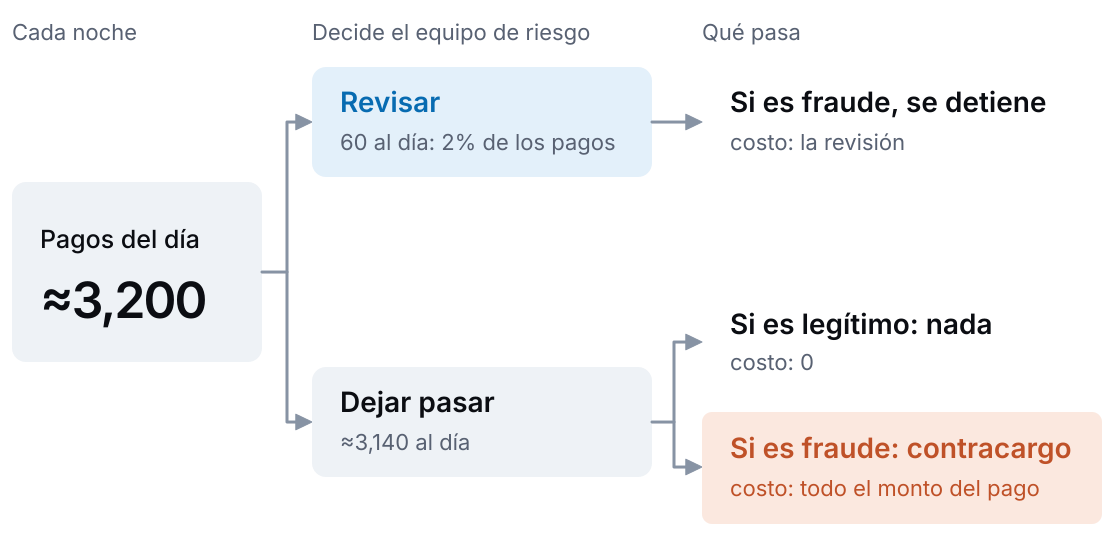

In [2]:
fig("arbol")

**La matriz de confusión en dólares.** La métrica de la decisión es una sola celda:

| | El pago es fraude | El pago es legítimo |
|---|---|---|
| Se revisa | Fraude detenido: **la métrica que se maximiza** | Una revisión usada sin recuperar nada |
| No se revisa | Contracargo: se pierde el monto completo | Sin costo |

**Cómo se ordena la cola.** El modelo estima la probabilidad de fraude de cada pago y la multiplica por el monto: el
resultado es el fraude esperado en dólares. Cada noche se revisan los 60 pagos con mayor fraude esperado. La figura
muestra un día real de la prueba (día 166) con las probabilidades del modelo congelado; la sección 5.1 comprueba que
esas probabilidades están calibradas.

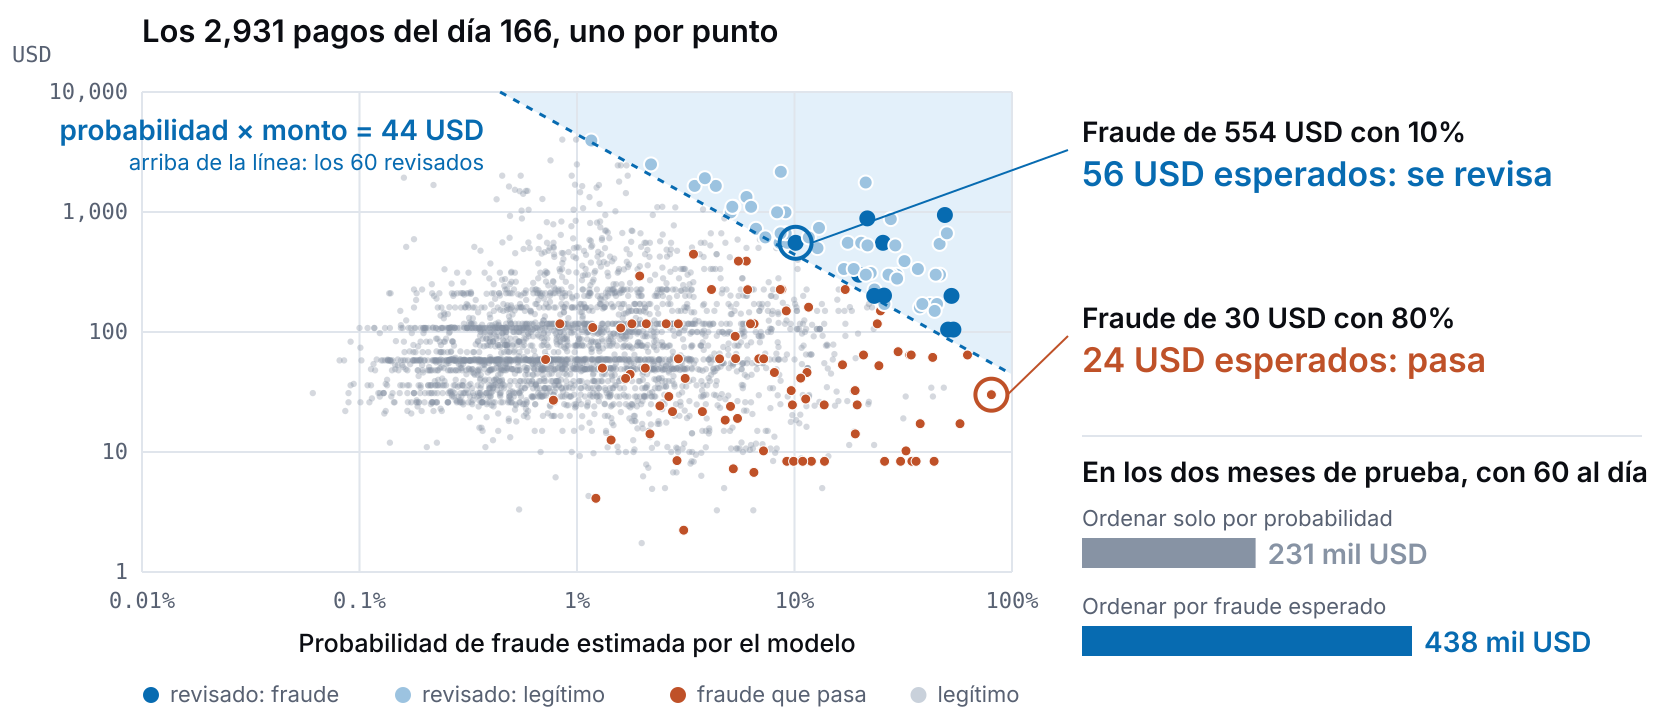

In [3]:
fig("cola_dia")

**Cómo leer la línea.** Es el corte del día: arriba quedan los 60 pagos con mayor fraude esperado (44 USD o más).
Un fraude de 30 USD con 80% de probabilidad vale 24 USD esperados y queda abajo; uno de 554 USD con 10% vale 56 y
entra. Por eso pasan fraudes con probabilidad alta: son pagos chicos, y la cola los cambia por pagos caros de
probabilidad media. **Es la regla óptima para este objetivo**: si cada revisión cuesta lo mismo y las probabilidades
están calibradas, el fraude esperado de la cola es la suma de probabilidad × monto de sus pagos, y los 60 con mayor
producto maximizan esa suma. La sección 5.1 lo mide: en los dos meses de prueba, ordenar por fraude esperado detiene
casi el doble de dólares que ordenar solo por probabilidad.

### 1.2 Objetivos

- **Objetivo de negocio.** Detener más dólares de fraude con las mismas 60 revisiones diarias: el mismo equipo y el
  mismo cupo; solo cambia qué pagos entran a la cola.
- **Objetivo de minería de datos.** Estimar, con la información disponible al cierre del día, la probabilidad de que
  cada pago sea fraude, y ordenar la cola por probabilidad × monto.
- **Impacto esperado.** El periodo de desarrollo (días 61–120) dio la referencia antes de abrir la prueba: cuánto fraude
  detenía el modelo elegido y su ventaja contra la mejor regla y la mejor logística.

In [4]:
ib = S["info_bloques"]
pd.DataFrame({b: {"fraude del bloque (mil USD)": mil(ib[b]["usd_fraude"]), "modelo (mil USD)": mil(S["dolares"][FINAL][b]),
                  "mejor regla (mil USD)": mil(S["dolares"][REGLA][b]), "mejor logística (mil USD)": mil(S["dolares"][LOGIT][b]),
                  "ventaja contra la regla": pc(S["ventaja"][REGLA][b]), "ventaja contra la logística": pc(S["ventaja"][LOGIT][b])}
              for b in ("D1", "D2")}).rename(columns={"D1": "D1: días 61–90", "D2": "D2: días 91–120"})

,D1: días 61–90,D2: días 91–120
fraude del bloque (mil USD),523.6,658.9
modelo (mil USD),183.7,264.2
mejor regla (mil USD),73.3,201.5
mejor logística (mil USD),142.8,254.2
ventaja contra la regla,+150.6%,+31.1%
ventaja contra la logística,+28.7%,+3.9%


### 1.3 Criterios de éxito

El éxito se mide en dólares de fraude dentro de la cola, con el mismo cupo, en dos meses que no se usaron para ninguna
decisión (días 121–151 y 152–182). Las metas se fijaron antes de abrir la prueba (`docs/protocolo.md`) y se piden en
**cada** mes:

In [5]:
U = R["umbrales"]
pd.DataFrame({"Comparador": ["Mejor regla (práctica actual)", "Mejor logística (misma información)", "Mismo modelo ordenado solo por probabilidad"],
              "Condición": [f"ventaja ≥ {U['H1']:.0%} y límite inferior del IC 95% > 0", f"ventaja ≥ {U['H2']:.0%} y límite inferior del IC 95% > 0",
                            "límite inferior del IC 95% > 0"]}, index=["H1", "H2", "H3"])

,Comparador,Condición
H1,Mejor regla (práctica actual),ventaja ≥ 20% y límite inferior del IC 95% > 0
H2,Mejor logística (misma información),ventaja ≥ 10% y límite inferior del IC 95% > 0
H3,Mismo modelo ordenado solo por probabilidad,límite inferior del IC 95% > 0


**El caso tiene éxito si H1, H2 y H3 se cumplen en los dos meses.** El intervalo pareado (bootstrap de días) descarta
que la ventaja sea azar de qué días cayeron en la prueba. El criterio no es el AUC: un AUC más alto no implica más
dinero detenido (sección 5.1).

## 2. Comprensión de los datos

### 2.1 Fuentes de datos

- **Origen.** Pagos reales de comercio electrónico de Vesta Corporation, publicados para la competencia
  *IEEE-CIS Fraud Detection* (Kaggle, 2019). Se usa el archivo de entrenamiento, el único con etiqueta: transacciones
  e identidad unidas, 590,540 pagos en 182 días.
- **Cómo se obtuvieron.** De la copia pública en OpenML (conjunto 46858, en Parquet), que no pide cuenta de Kaggle.
  `scripts/00_descargar.py` la baja y compara su huella SHA-256 con la registrada en `datos/fuente.json`; si no
  coincide, descarta el archivo.
- **Etiqueta.** `isFraud` sigue la regla de Vesta: un pago con contracargo es fraude, y la marca se propaga a los pagos
  posteriores de la misma cuenta, dirección o correo.
- **Tiempo.** `TransactionDT` cuenta segundos desde una fecha de referencia que Vesta no publica: hay día y hora
  relativos, no fechas de calendario.

In [6]:
display(pd.Series(FUENTE).rename("datos/fuente.json").to_frame())
codigo(verificar_fuente)
verificar_fuente()
meta = pq.ParquetFile(ARCHIVO).metadata
print(f"Huella SHA-256 verificada: {meta.num_rows:,} pagos y {meta.num_columns} columnas.")

,datos/fuente.json
conjunto,"IEEE-CIS Fraud Detection (Vesta), archivo de entrenamiento unido (transacciones + identidad)"
copia,OpenML 46858
pagina,https://www.openml.org/d/46858
url,https://data.openml.org/datasets/0004/46858/dataset_46858.pq
competencia,https://www.kaggle.com/competitions/ieee-fraud-detection
sha256,c313ad335223589693e26d5808267ed6ff03d871be5d9bb63deb3b847fa4b891
bytes,78250805


`src/revisar/datos.py` · `verificar_fuente`

```python
def verificar_fuente() -> None:
    h = hashlib.sha256(ARCHIVO.read_bytes()).hexdigest()
    if h != FUENTE["sha256"]:
        raise SystemExit(f"El archivo de datos no coincide con datos/fuente.json: {h}")
```

Huella SHA-256 verificada: 590,540 pagos y 456 columnas.


**Las columnas, por grupo.** Vesta enmascara el significado de muchas: `card1–card6`, `addr`, `M1–M9` e `id_*`
tienen nombre genérico, y las columnas `C`, `D2–D15` y `V` son conteos y medidas propias de Vesta que la descripción
pública no explica.

In [7]:
cols = pq.read_schema(ARCHIVO).names
grupos = {"Etiqueta": ["isFraud"], "Tiempo": ["TransactionDT"], "Monto y producto": ["TransactionAmt", "ProductCD"],
          "Tarjeta": [c for c in cols if c.startswith("card")], "Dirección y distancia": ["addr1", "addr2", "dist1", "dist2"],
          "Correo": ["P_emaildomain", "R_emaildomain"], "Coincidencias M1–M9": [f"M{i}" for i in range(1, 10)],
          "Dispositivo e identidad": ["DeviceType", "DeviceInfo"] + [c for c in cols if c.startswith("id_")],
          "Antigüedad de la cuenta (D1)": ["D1"], "Opacas de Vesta (C1–C14, D2–D15, V1–V339)": VESTA,
          "Vacías en esta copia (id-01 a id-38, con guion)": [c for c in cols if c.startswith("id-")]}
vacias = pq.read_table(ARCHIVO, columns=grupos["Vacías en esta copia (id-01 a id-38, con guion)"])
assert all(vacias[c].null_count == vacias.num_rows for c in vacias.column_names), "las columnas id-xx deben estar vacías"
otras = [c for c in cols if not any(c in v for v in grupos.values())]
usa = set(NUM + CAT + ["D1"])
display(pd.DataFrame({"columnas": {g: len(v) for g, v in grupos.items()},
                      "las usa el modelo": {g: sum(c in usa for c in v) for g, v in grupos.items()},
                      "ejemplos": {g: ", ".join(v[:5]) + (" …" if len(v) > 5 else "") for g, v in grupos.items()}}))
print("Otras columnas:", otras or "ninguna")

,columnas,las usa el modelo,ejemplos
Etiqueta,1,0,isFraud
Tiempo,1,0,TransactionDT
Monto y producto,2,2,"TransactionAmt, ProductCD"
Tarjeta,6,6,"card1, card2, card3, card4, card5 …"
Dirección y distancia,4,4,"addr1, addr2, dist1, dist2"
Correo,2,2,"P_emaildomain, R_emaildomain"
Coincidencias M1–M9,9,9,"M1, M2, M3, M4, M5 …"
Dispositivo e identidad,40,40,"DeviceType, DeviceInfo, id_01, id_02, id_03 …"
Antigüedad de la cuenta (D1),1,1,D1
"Opacas de Vesta (C1–C14, D2–D15, V1–V339)",367,0,"C1, C2, C3, C4, C5 …"


Otras columnas: ninguna


**Carga de los días 1 a 120.** `cargar(hasta_dia)` filtra por tiempo al leer el archivo: en las secciones 2 y 3 los
días de la prueba (121–182) ni siquiera se cargan. Su código está en la sección 3.2.

In [8]:
t0 = time.time()
dev = cargar(121)
assert dev["dia"].max() < 121
print(f"Días {dev['dia'].min()}–{dev['dia'].max()}: {len(dev):,} pagos y {dev.shape[1]} columnas, cargados en {time.time() - t0:.0f} s")

Días 1–120: 414,542 pagos y 97 columnas, cargados en 8 s


### 2.2 Análisis exploratorio (días 1–120)

**Estadísticas generales.**

In [9]:
uf = dev["TransactionAmt"] * dev["fraude"]          # dólares de fraude de cada pago
pagos_dia = dev.groupby("dia").size()
pd.Series({"Pagos": f"{len(dev):,}", "Días": dev["dia"].nunique(), "Pagos por día (mediana)": f"{pagos_dia.median():,.0f}",
           "Tasa de fraude": f"{dev['fraude'].mean():.2%}", "Dólares cobrados (millones)": f"{dev['TransactionAmt'].sum() / 1e6:,.1f}",
           "Dólares de fraude (miles)": f"{uf.sum() / 1e3:,.0f}", "Parte de los dólares que es fraude": f"{uf.sum() / dev['TransactionAmt'].sum():.2%}",
           "Cupo de 60 como parte de los pagos del día": f"{60 / pagos_dia.median():.1%}"}).to_frame("valor")

,valor
Pagos,"414,542"
Días,120
Pagos por día (mediana),"3,180"
Tasa de fraude,3.52%
Dólares cobrados (millones),55.8
Dólares de fraude (miles),"2,134"
Parte de los dólares que es fraude,3.82%
Cupo de 60 como parte de los pagos del día,1.9%


**Estadísticas descriptivas por clase.** Monto, hora, antigüedad de la cuenta y el historial del cliente (que se
construye en la sección 3.2).

In [10]:
variables = {"Monto (USD)": dev["TransactionAmt"], "Hora del día": dev["hora"], "Días desde el alta (D1)": dev["D1"],
             "Distancia (dist1)": dev["dist1"], "Pagos previos del cliente": dev["h_cliente_previos"],
             "Horas desde su pago anterior": dev["h_cliente_segundos_desde"] / 3600}
filas = {}
for nombre, v in variables.items():
    for clase, msk in (("fraude", dev["fraude"] == 1), ("legítimo", dev["fraude"] == 0)):
        w = v[msk].dropna()
        filas[(nombre, clase)] = {"con dato": w.size / msk.sum(), "media": w.mean(), "p10": w.quantile(.1), "p25": w.quantile(.25),
                                  "mediana": w.median(), "p75": w.quantile(.75), "p90": w.quantile(.9)}
pd.DataFrame.from_dict(filas, orient="index").round(2)

con dato   media    p10    p25  mediana     p75     p90
Monto (USD)                  fraude        1.00  146.15  19.24  34.92    76.02  171.00  335.00
                             legítimo      1.00  134.28  25.95  43.95    68.95  125.00  270.00
Hora del día                 fraude        1.00   13.34   1.00   5.00    16.00   20.00   22.00
                             legítimo      1.00   13.84   1.00   6.00    16.00   20.00   22.00
Días desde el alta (D1)      fraude        1.00   37.86   0.00   0.00     0.00   11.00  132.00
                             legítimo      1.00   89.65   0.00   0.00     1.00  115.00  356.00
Distancia (dist1)            fraude        0.22  181.32   1.00   3.00    11.00   75.00  683.90
                             legítimo      0.39  123.96   1.00   3.00     9.00   25.00  305.00
Pagos previos del cliente    fraude        1.00    6.16   0.00   0.00     2.00    7.00   17.00
                             legítimo      1.00    3.96   0.00   0.00     1.00    4.00   10.00
Horas desde su pago anterior fraude        0.70   60.74   0.02   0.10     1.92   25.04  161.41
                             legítimo      0.60  198.60   0.08   0.86    28.06  263.54  646.95

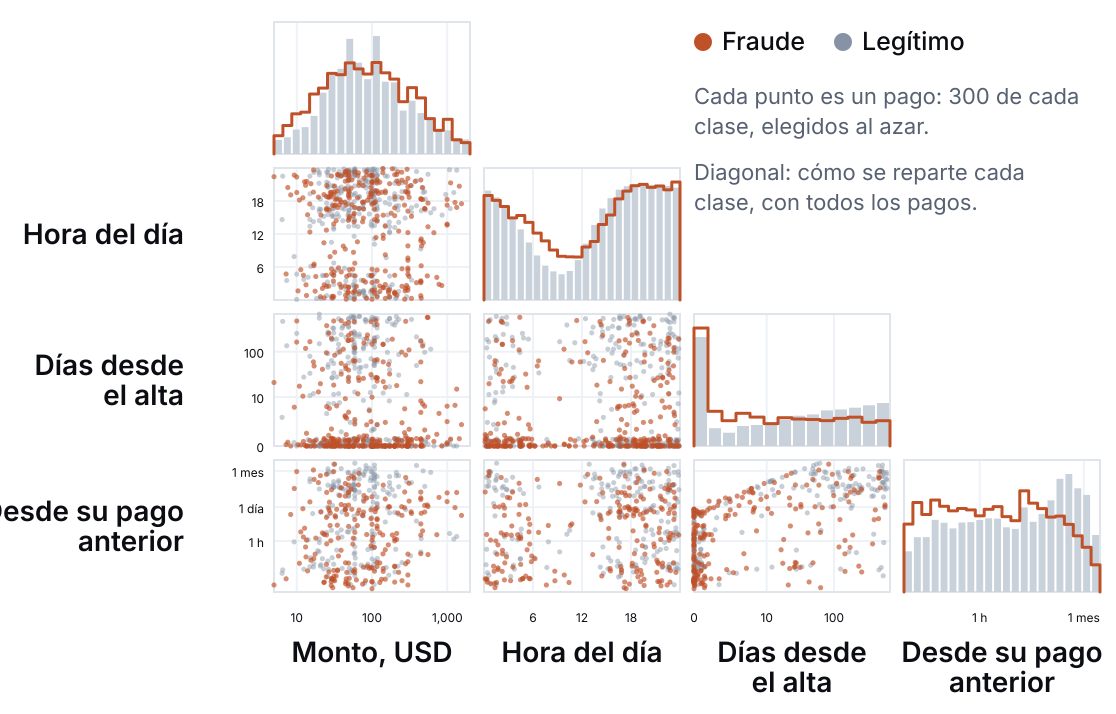

In [11]:
fig("eda_matriz")

La matriz de dispersión usa 300 fraudes y 300 legítimos al azar; la diagonal tiene el histograma de cada clase. En
cada par de variables las nubes se enciman: ningún corte simple separa el fraude.

**Tasa de fraude por categoría.**

In [12]:
def por_categoria(col, n=6):
    g = pd.DataFrame({"pagos": dev.groupby(col).size(), "tasa de fraude": dev.groupby(col)["fraude"].mean(),
                      "parte del fraude en USD": uf.groupby(dev[col]).sum() / uf.sum()})
    return g.sort_values("pagos", ascending=False).head(n)


cat = pd.concat({c: por_categoria(c) for c in ("ProductCD", "card4", "card6", "DeviceType")}, names=["variable", "categoría"])
cat.assign(pagos=cat["pagos"].map("{:,}".format), **{"tasa de fraude": cat["tasa de fraude"].map("{:.1%}".format),
                                                     "parte del fraude en USD": cat["parte del fraude en USD"].map("{:.0%}".format)})

pagos tasa de fraude parte del fraude en USD
variable   categoría                                                       
ProductCD  W                 298,873           2.1%                     64%
           C                  50,136          11.2%                     13%
           R                  30,185           3.5%                     12%
           H                  28,134           4.5%                     10%
           S                   7,214           6.0%                      2%
card4      visa              270,809           3.5%                     65%
           mastercard        131,383           3.6%                     29%
           american express    6,750           2.8%                      1%
           discover            4,771           6.6%                      5%
           NA                    829           3.1%                      0%
card6      debit             304,108           2.4%                     46%
           credit            109,564           6.6%                     54%
           NA                    826           2.9%                      0%
           debit or credit        29           0.0%                      0%
           charge card            15           0.0%                      0%
DeviceType NA                306,964           2.1%                     65%
           desktop            66,059           6.0%                     15%
           mobile             41,519           9.9%                     19%

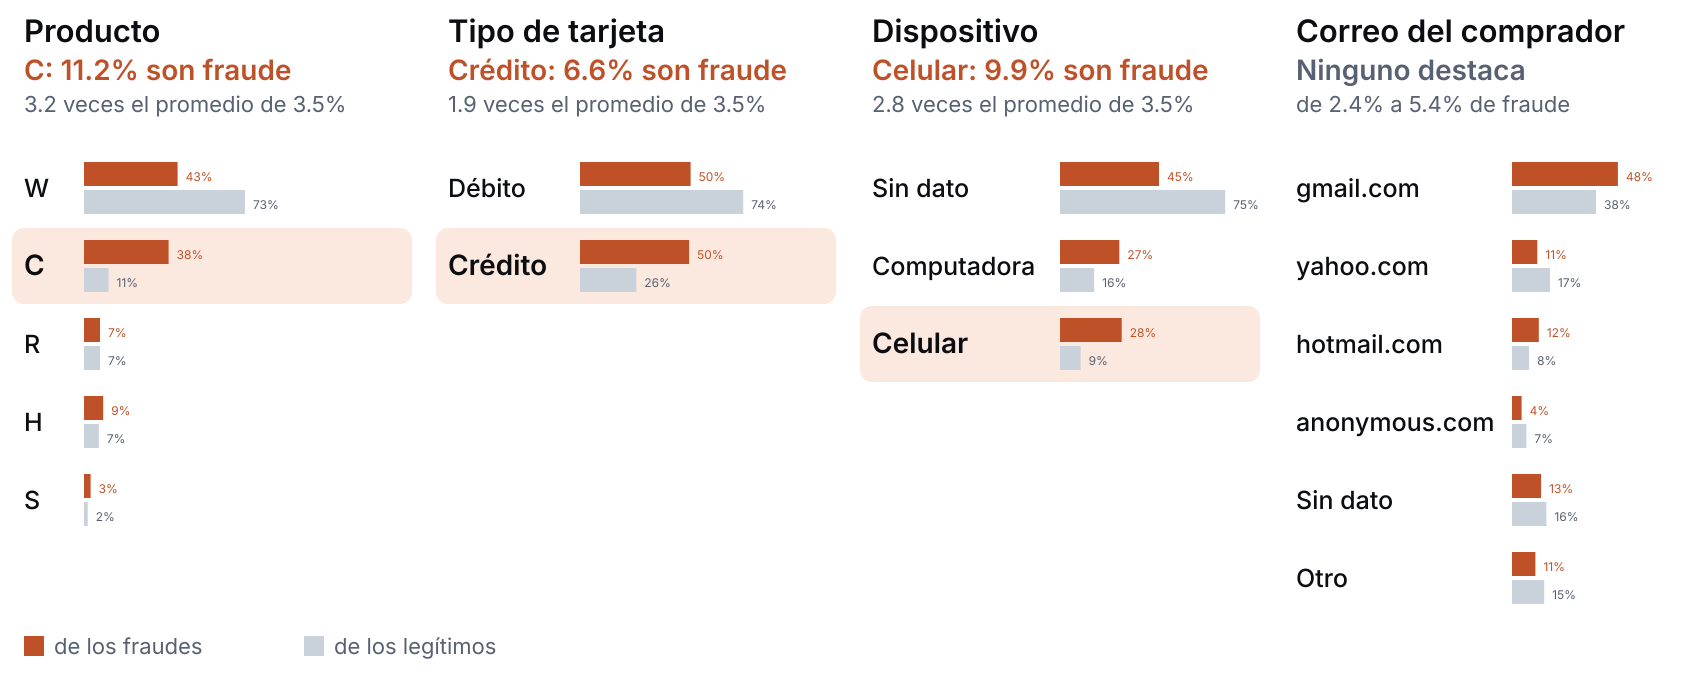

In [13]:
fig("eda_clases")

**Dónde está el dinero: deciles de monto.**

In [14]:
decil = pd.qcut(dev["TransactionAmt"].rank(method="first"), 10, labels=range(1, 11))
dd = pd.DataFrame({"monto máximo (USD)": dev.groupby(decil)["TransactionAmt"].max(), "tasa de fraude": dev.groupby(decil)["fraude"].mean(),
                   "parte del fraude en USD": uf.groupby(decil).sum() / uf.sum()}).rename_axis("decil de monto")
dd.assign(**{"tasa de fraude": dd["tasa de fraude"].map("{:.1%}".format), "parte del fraude en USD": dd["parte del fraude en USD"].map("{:.0%}".format)})

,monto máximo (USD),tasa de fraude,parte del fraude en USD
decil de monto,,,
1,25.950,5.6%,2%
2,35.950,3.4%,2%
3,49.000,3.2%,3%
4,57.950,2.3%,2%
5,68.950,2.4%,3%
6,100.000,3.6%,6%
7,117.000,1.9%,4%
8,160.500,3.6%,10%
9,280.000,4.0%,16%


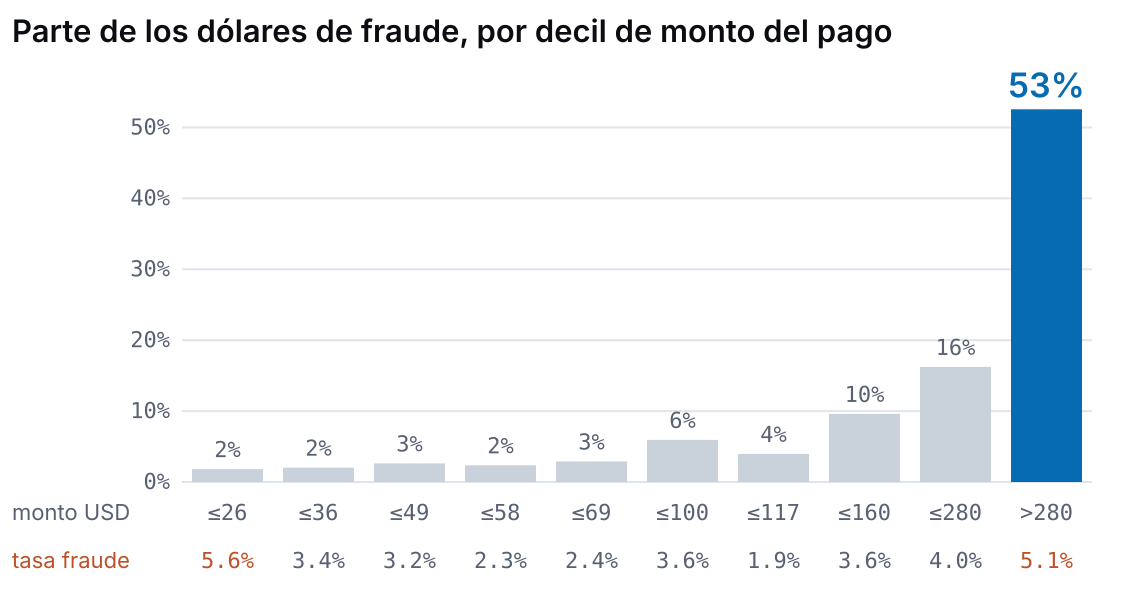

In [15]:
fig("deciles")

**En el tiempo.** Pagos y tasa de fraude por día.

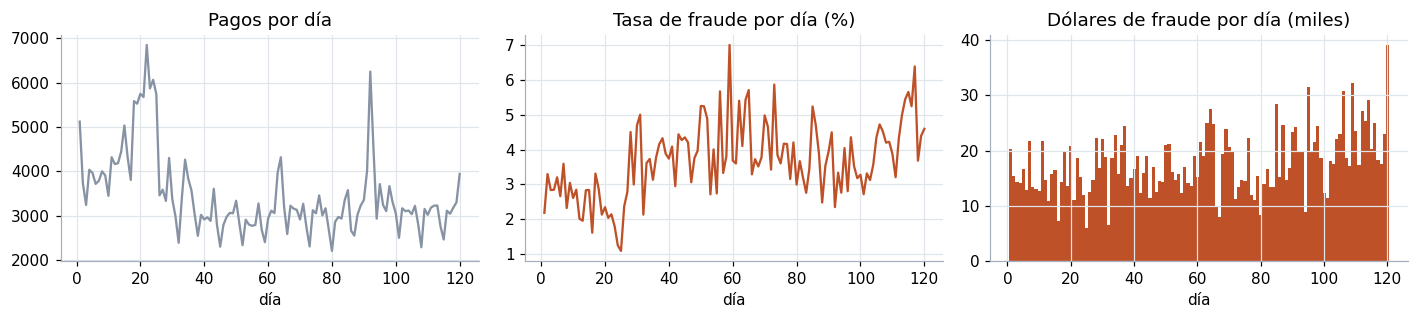

Tasa diaria de fraude: de 1.1% a 7.0%; fraude diario: mediana 16,980 USD, máximo 39,055 USD


In [16]:
dia = pd.DataFrame({"pagos": pagos_dia, "tasa": dev.groupby("dia")["fraude"].mean(), "usd": uf.groupby(dev["dia"]).sum()})
f, ax = plt.subplots(1, 3, figsize=(13, 3))
ax[0].plot(dia.index, dia["pagos"], color=GRIS); ax[0].set_title("Pagos por día")
ax[1].plot(dia.index, dia["tasa"] * 100, color=NARANJA); ax[1].set_title("Tasa de fraude por día (%)")
ax[2].bar(dia.index, dia["usd"] / 1e3, color=NARANJA, width=1); ax[2].set_title("Dólares de fraude por día (miles)")
for a in ax:
    a.set_xlabel("día")
plt.tight_layout(); plt.show()
print(f"Tasa diaria de fraude: de {dia['tasa'].min():.1%} a {dia['tasa'].max():.1%}; "
      f"fraude diario: mediana {dia['usd'].median():,.0f} USD, máximo {dia['usd'].max():,.0f} USD")

In [17]:
fr, lg = dev["fraude"] == 1, dev["fraude"] == 0
alta_1_7 = dev.loc[dev["D1"].between(1, 7), "fraude"].mean()
horas = dev.groupby("hora")["fraude"].mean()
Markdown(f'''**Hallazgos iniciales**

1. **El fraude es raro y caro.** {dev['fraude'].mean():.1%} de los pagos es fraude, pero suma {uf.sum() / 1e3:,.0f} mil USD en
   120 días, unos {dia['usd'].median():,.0f} USD en un día típico. El cupo de 60 revisa cerca de {60 / pagos_dia.median():.0%} de los pagos.
2. **El monto solo no separa, pero decide cuánto cuesta cada fraude.** La mediana es {dev.loc[fr, 'TransactionAmt'].median():.0f} USD en fraude
   y {dev.loc[lg, 'TransactionAmt'].median():.0f} en legítimos, y el decil de mayor monto concentra {dd['parte del fraude en USD'].iloc[-1]:.0%} del
   fraude en dólares: la cola debe ordenarse por dinero, no solo por probabilidad.
3. **El historial del cliente separa mucho.** Entre su pago anterior y el actual pasan
   {(dev.loc[fr, 'h_cliente_segundos_desde'] / 3600).median():.1f} h (mediana) en fraude y {(dev.loc[lg, 'h_cliente_segundos_desde'] / 3600).median():.0f} h en legítimos.
4. **Las cuentas nuevas son de riesgo.** Con 1 a 7 días desde el alta, {alta_1_7:.1%} de los pagos es fraude; el promedio es {dev['fraude'].mean():.1%}.
5. **Tres categorías destacan:** el producto C, la tarjeta de crédito y el celular. La tasa por hora va de {horas.min():.1%} a {horas.max():.1%}.
6. **Ninguna variable separa sola el fraude:** hace falta un modelo que combine muchas.''')

**Hallazgos iniciales**

1. **El fraude es raro y caro.** 3.5% de los pagos es fraude, pero suma 2,134 mil USD en
   120 días, unos 16,980 USD en un día típico. El cupo de 60 revisa cerca de 2% de los pagos.
2. **El monto solo no separa, pero decide cuánto cuesta cada fraude.** La mediana es 76 USD en fraude
   y 69 en legítimos, y el decil de mayor monto concentra 53% del
   fraude en dólares: la cola debe ordenarse por dinero, no solo por probabilidad.
3. **El historial del cliente separa mucho.** Entre su pago anterior y el actual pasan
   1.9 h (mediana) en fraude y 28 h en legítimos.
4. **Las cuentas nuevas son de riesgo.** Con 1 a 7 días desde el alta, 9.8% de los pagos es fraude; el promedio es 3.5%.
5. **Tres categorías destacan:** el producto C, la tarjeta de crédito y el celular. La tasa por hora va de 2.2% a 10.0%.
6. **Ninguna variable separa sola el fraude:** hace falta un modelo que combine muchas.

### 2.3 Calidad de los datos

**Valores faltantes.** Son muchos en dispositivo, identidad y distancia: Vesta no siempre recibe esos campos.

In [18]:
falta = pd.concat([dev[NUM + ["D1"]].isna().mean(), (dev[CAT] == "NA").mean()])


def grupo(c):
    if c.startswith(("id_", "Device")):
        return "Dispositivo e identidad"
    if c.startswith("card"):
        return "Tarjeta"
    if c[0] == "M" and c[1:].isdigit():
        return "Coincidencias M1–M9"
    if c.startswith(("addr", "dist")):
        return "Dirección y distancia"
    return "Correo" if "email" in c else "Monto, producto y D1"


g = falta.groupby(falta.index.map(grupo))
display(pd.DataFrame({"columnas": g.size(), "faltante medio": g.mean().map("{:.0%}".format),
                      "columnas con más de 50% faltante": g.apply(lambda s: int((s > .5).sum()))}))
inf = {}
for c in ("DeviceType", "id_01", "dist1", "P_emaildomain", "addr1", "D1"):
    nulo = dev[c].isna() if c in NUM + ["D1"] else dev[c] == "NA"
    inf[c] = {"faltante": f"{nulo.mean():.1%}", "tasa de fraude si falta": f"{dev.loc[nulo, 'fraude'].mean():.1%}",
              "tasa de fraude con dato": f"{dev.loc[~nulo, 'fraude'].mean():.1%}"}
pd.DataFrame(inf).T

,columnas,faltante medio,columnas con más de 50% faltante
Coincidencias M1–M9,9,56%,7
Correo,2,45%,1
Dirección y distancia,4,44%,2
Dispositivo e identidad,40,83%,40
"Monto, producto y D1",3,0%,0
Tarjeta,6,0%,0


,faltante,tasa de fraude si falta,tasa de fraude con dato
DeviceType,74.0%,2.1%,7.5%
id_01,73.4%,2.1%,7.3%
dist1,61.8%,4.5%,2.0%
P_emaildomain,15.6%,3.0%,3.6%
addr1,11.5%,11.3%,2.5%
D1,0.1%,0.4%,3.5%


El faltante no es al azar: la tasa de fraude cambia según falte o no el dato. Por eso se conserva como información
(sección 3.1) en vez de borrar filas o columnas.

**Ruido e inconsistencias.**

In [19]:
centavos3 = (np.round(dev["TransactionAmt"] * 100, 6) % 1) > 0
mismo_seg = dev.duplicated(["card1", "addr1", "TransactionDT"], keep=False)
ck = X["cliente"]
pd.DataFrame([
    ("Filas duplicadas en todas las columnas", f"{int(dev.duplicated(NUM + CAT + ['TransactionDT', 'D1']).sum()):,}", "Se conservan: pueden ser cobros repetidos reales."),
    ("Pagos de la misma tarjeta y dirección en el mismo segundo", f"{int(mismo_seg.sum()):,}", "El historial solo cuenta segundos estrictamente anteriores: no se ven entre sí."),
    ("Montos menores o iguales a cero", f"{int((dev['TransactionAmt'] <= 0).sum()):,}", "Nada que corregir."),
    ("Montos con más de dos decimales", f"{centavos3.mean():.1%}", "Cobros convertidos de otra moneda: la variable centavos lo captura."),
    ("Categorías con un solo pago en card1 y DeviceInfo", f"{int((dev['card1'].value_counts() == 1).sum()):,} y {int((dev['DeviceInfo'].value_counts() == 1).sum()):,}",
     "Las categorías con menos de 50 casos se agrupan al codificar."),
    ("Días sin pagos entre el primero y el 120", f"{int(dev['dia'].max() - dev['dia'].min() + 1 - dev['dia'].nunique())}", "Serie diaria completa."),
    ("Fraudes que ocurren en clientes con dos o más pagos", f"{ck['fraudes_en_clientes_con_2_o_mas']:.0%}", "Etiqueta propagada: el historial del cliente pesa mucho."),
    ("Clientes con fraude en los que todos sus pagos son fraude", f"{ck['clientes_con_fraude_todo_fraude']:.0%}", "Ruido de etiqueta: se marca la cuenta, no cada pago revisado."),
], columns=["chequeo", "resultado", "qué se hace"]).set_index("chequeo")

,resultado,qué se hace
chequeo,,
Filas duplicadas en todas las columnas,60,Se conservan: pueden ser cobros repetidos reales.
Pagos de la misma tarjeta y dirección en el mismo segundo,140,El historial solo cuenta segundos estrictamente anteriores: no se ven entre sí.
Montos menores o iguales a cero,0,Nada que corregir.
Montos con más de dos decimales,10.9%,Cobros convertidos de otra moneda: la variable centavos lo captura.
Categorías con un solo pago en card1 y DeviceInfo,"3,301 y 399",Las categorías con menos de 50 casos se agrupan al codificar.
Días sin pagos entre el primero y el 120,0,Serie diaria completa.
Fraudes que ocurren en clientes con dos o más pagos,77%,Etiqueta propagada: el historial del cliente pesa mucho.
Clientes con fraude en los que todos sus pagos son fraude,62%,"Ruido de etiqueta: se marca la cuenta, no cada pago revisado."


## 3. Preparación de los datos

### 3.1 Limpieza: nulos y valores extremos

| Problema | Decisión | Por qué |
|---|---|---|
| Numéricas faltantes | Mediana del entrenamiento + una columna indicadora `falta_*` | El faltante es informativo (2.3); la mediana sale solo del entrenamiento |
| Categóricas faltantes | Categoría propia `NA` | Igual: falta el dato ≠ dato desconocido |
| Árboles de scikit-learn | Faltante = −999, fuera del rango de los datos | El árbol puede separarlo en su propia rama |
| Montos extremos | Se conservan | Ahí está el dinero (tabla de abajo); la sección 5.2 repite la evaluación sin ellos |
| Escala muy sesgada | Transformación por cuantiles a una normal | Para la logística y la red; los árboles no la necesitan |
| Categorías raras | Se agrupan si tienen menos de 50 pagos | Evita columnas de un solo caso |

**¿Qué pasaría al quitar los montos extremos?**

In [20]:
monto = dev["TransactionAmt"]
q1, q3 = monto.quantile([.25, .75])
tope_iqr, p99 = q3 + 1.5 * (q3 - q1), monto.quantile(.99)
display(monto.describe(percentiles=[.25, .5, .75, .9, .99, .999]).to_frame("monto (USD)").T.round(1))
pd.DataFrame({"parte de los pagos": [f"{(monto > tope_iqr).mean():.1%}", f"{(monto > p99).mean():.1%}"],
              "parte del fraude en USD": [f"{uf[monto > tope_iqr].sum() / uf.sum():.0%}", f"{uf[monto > p99].sum() / uf.sum():.0%}"]},
             index=[f"Sobre Q3 + 1.5·IQR ({tope_iqr:,.0f} USD)", f"Sobre el percentil 99 ({p99:,.0f} USD)"])

,count,mean,std,min,25%,50%,75%,90%,99%,99.9%,max
monto (USD),414542.0,134.7,238.4,0.3,43.0,69.0,125.0,280.0,1104.0,2749.6,31937.4


,parte de los pagos,parte del fraude en USD
Sobre Q3 + 1.5·IQR (248 USD),11.4%,56%
"Sobre el percentil 99 (1,104 USD)",0.9%,7%


La regla de 1.5·IQR marcaría como atípicos los pagos que concentran una parte grande del fraude en dólares: borrarlos
quitaría justo lo que la cola debe atrapar. Se conservan, y la sección 5.2 comprueba que la ventaja del modelo no
depende de ellos.

### 3.2 Ingeniería de características

| Variable nueva | Cómo se calcula | Por qué |
|---|---|---|
| `log_monto`, `centavos` | log(1 + monto); parte decimal del monto | Escala; cobros convertidos de otra moneda |
| `hora`, `dia_semana` | Desde `TransactionDT` | El fraude cambia con la hora (2.2) |
| `alta` | Día del pago − `D1` | Fecha de alta de la cuenta: con tarjeta y dirección arma el **cliente** |
| Historial por llave, 25 variables | 5 medidas × 5 llaves, solo con pagos de segundos anteriores | Velocidad y recencia: la señal más fuerte del EDA |

Las cinco medidas por llave: pagos previos, pagos en las últimas 24 horas y en los últimos 7 días, segundos desde el
pago anterior y monto contra el promedio previo. Ninguna usa la etiqueta.

In [21]:
for k, v in CLAVES.items():
    print(f"llave {k:<20} {' + '.join(v)}")
print("medidas por llave:", ", ".join(ESTADISTICAS))
hist = [c for c in dev.columns if c.startswith("h_")]
print(f"{len(DERIVADAS)} derivadas ({', '.join(DERIVADAS)}) y {len(hist)} de historial, por ejemplo {hist[:3]}")

llave tarjeta              card1
llave tarjeta_dir          card1 + addr1
llave tarjeta_dir_correo   card1 + addr1 + P_emaildomain
llave tarjeta_completa     card1 + card2 + card3 + card4 + card5 + card6
llave cliente              card1 + addr1 + alta
medidas por llave: previos, ultimo_dia, ultima_semana, segundos_desde, razon_monto
4 derivadas (log_monto, centavos, hora, dia_semana) y 25 de historial, por ejemplo ['h_tarjeta_previos', 'h_tarjeta_ultimo_dia', 'h_tarjeta_ultima_semana']


In [22]:
codigo(cargar, _historial)

`src/revisar/datos.py` · `cargar`

```python
def cargar(hasta_dia: int, vesta: bool = False) -> pd.DataFrame:
    """Pagos de los días 1 a hasta_dia - 1, ordenados en el tiempo, con variables derivadas e historial."""
    cols = ["isFraud", "TransactionDT"] + NUM + CAT + ["D1"] + (VESTA if vesta else [])
    tabla = pq.read_table(ARCHIVO, columns=cols, filters=[("TransactionDT", "<", hasta_dia * DIA)])
    df = tabla.to_pandas()
    assert df["TransactionDT"].max() < hasta_dia * DIA
    df["fraude"] = df.pop("isFraud").astype(str).astype(float).astype(int)
    df = df.sort_values("TransactionDT", kind="stable").reset_index(drop=True)
    t = df["TransactionDT"].to_numpy(np.int64)
    monto = df["TransactionAmt"].to_numpy(float)
    df["dia"] = (t // DIA).astype(int)
    df["hora"] = ((t % DIA) // 3600).astype(float)
    df["dia_semana"] = (df["dia"] % 7).astype(float)
    df["centavos"] = np.round(monto - np.floor(monto), 3)
    df["log_monto"] = np.log1p(monto)
    df["alta"] = np.floor(df["dia"] - df["D1"])
    for c in CAT:
        df[c] = df[c].astype(str).replace({"nan": "NA", "None": "NA"})
    for nombre, campos in CLAVES.items():
        clave = df[campos[0]].astype(str)
        for c in campos[1:]:
            clave = clave + "|" + df[c].astype(str)
        codigos, _ = pd.factorize(clave)
        for e, v in _historial(t, monto, codigos).items():
            df[f"h_{nombre}_{e}"] = v
    return df
```

`src/revisar/datos.py` · `_historial`

```python
def _historial(t: np.ndarray, monto: np.ndarray, codigos: np.ndarray) -> dict[str, np.ndarray]:
    """Recencia, frecuencia y desvío del monto por clave, solo con pagos en segundos estrictamente anteriores."""
    base = np.int64(1 << 25)
    orden = np.lexsort((t, codigos))
    c = codigos[orden].astype(np.int64)
    ts = t[orden]
    a = monto[orden]
    k = c * base + ts
    inicio = np.searchsorted(k, c * base, side="left")
    antes = np.searchsorted(k, k, side="left")
    previos = antes - inicio
    hay = previos > 0
    acum = np.concatenate([[0.0], np.cumsum(a)])
    media_previa = np.where(hay, (acum[antes] - acum[inicio]) / np.maximum(previos, 1), np.nan)
    salida = {
        "previos": previos.astype(float),
        "ultimo_dia": (antes - np.searchsorted(k, c * base + np.maximum(ts - DIA, 0), side="left")).astype(float),
        "ultima_semana": (antes - np.searchsorted(k, c * base + np.maximum(ts - 7 * DIA, 0), side="left")).astype(float),
        "segundos_desde": np.where(hay, ts - ts[np.maximum(antes - 1, 0)], np.nan).astype(float),
        "razon_monto": np.where(hay, a / np.where(hay, media_previa, 1.0), np.nan),
    }
    inverso = np.empty_like(orden)
    inverso[orden] = np.arange(len(orden))
    return {e: v[inverso] for e, v in salida.items()}
```

**El historial, en vivo.** Cuatro pagos de un mismo cliente; los dos últimos ocurren en el mismo segundo y no se ven
entre sí.

In [23]:
t = np.array([0, 3_600, 90_000, 90_000])
montos = np.array([30.0, 40.0, 120.0, 10.0])
h = _historial(t, montos, np.zeros(4, int))
pd.DataFrame({"segundo": t, "monto": montos, **h}).rename(columns={"previos": "pagos previos", "ultimo_dia": "en 24 h",
    "ultima_semana": "en 7 días", "segundos_desde": "segundos desde el anterior", "razon_monto": "monto / promedio previo"})

,segundo,monto,pagos previos,en 24 h,en 7 días,segundos desde el anterior,monto / promedio previo
0,0,30.0,0.0,0.0,0.0,NaN,NaN
1,3600,40.0,1.0,1.0,1.0,3600.0,1.333
2,90000,120.0,2.0,1.0,2.0,86400.0,3.429
3,90000,10.0,2.0,1.0,2.0,86400.0,0.286


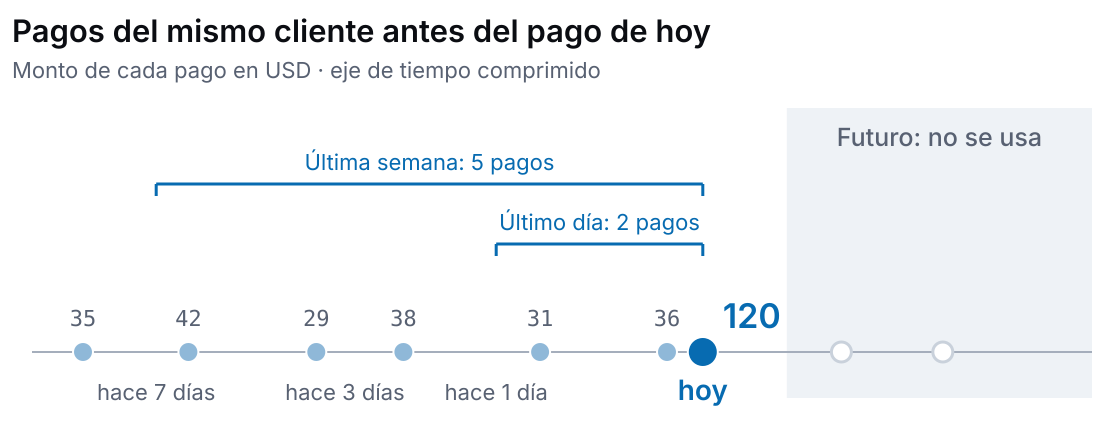

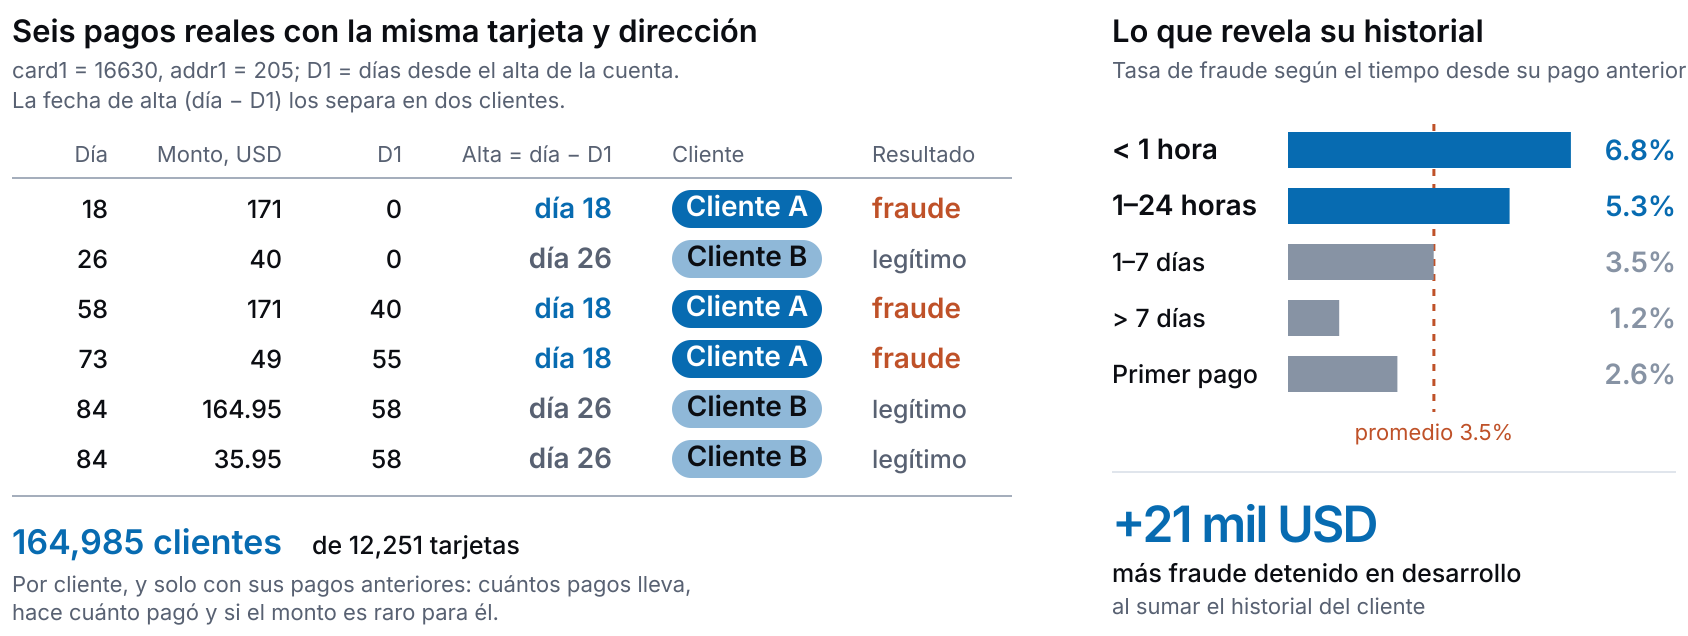

In [24]:
fig("tuberia", "cliente_armado")

**¿Separan las variables nuevas?** Tasa de fraude por tramos del historial del cliente, días 1–120.

In [25]:
horas_desde = dev["h_cliente_segundos_desde"] / 3600
tramo = pd.cut(horas_desde, [-.01, 1, 24, 24 * 7, np.inf], labels=["menos de 1 h", "1 h a 1 día", "1 a 7 días", "más de 7 días"])
tramo = tramo.cat.add_categories("primer pago").fillna("primer pago")
previos = pd.cut(dev["h_cliente_previos"], [-.5, .5, 2.5, 9.5, np.inf], labels=["0", "1 o 2", "3 a 9", "10 o más"])
for nombre, tr_ in (("tiempo desde su pago anterior", tramo), ("pagos previos del cliente", previos)):
    t_ = pd.DataFrame({"pagos": dev.groupby(tr_).size(), "tasa de fraude": dev.groupby(tr_)["fraude"].mean()}).rename_axis(nombre)
    display(t_.assign(pagos=t_["pagos"].map("{:,}".format), **{"tasa de fraude": t_["tasa de fraude"].map("{:.1%}".format)}))

,pagos,tasa de fraude
tiempo desde su pago anterior,,
menos de 1 h,"66,951",6.8%
1 h a 1 día,"56,774",5.3%
1 a 7 días,"47,310",3.5%
más de 7 días,"78,513",1.2%
primer pago,"164,994",2.6%


,pagos,tasa de fraude
pagos previos del cliente,,
0,"164,994",2.6%
1 o 2,"109,461",3.3%
3 a 9,"97,130",4.1%
10 o más,"42,957",6.3%


**Normalización y codificación: la matriz de diseño.** La clase `Diseno` aprende todo solo del entrenamiento:
mediana para imputar, transformación por cuantiles a normal, indicadores de faltante y una columna one-hot por
categoría con al menos 50 pagos. Los árboles de scikit-learn usan otra matriz: numéricas crudas y la frecuencia de cada
categoría.

In [26]:
codigo(Diseno)

`src/revisar/politicas.py` · `Diseno`

```python
class Diseno:
    """Matriz única para logística, XGBoost y red (cuantiles + faltantes + una columna por categoría con al
    menos 50 casos) y matriz nativa para árboles de sklearn (numéricas crudas + frecuencia de cada categoría)."""

    def __init__(self, tr: pd.DataFrame, conjunto: str):
        self.num, self.cat = CONJUNTOS[conjunto]
        X = tr[self.num].to_numpy(float)
        self.mediana = np.nanmedian(X, axis=0)
        self.mediana = np.where(np.isnan(self.mediana), 0.0, self.mediana)
        self.qt = QuantileTransformer(n_quantiles=200, output_distribution="normal", subsample=200_000, random_state=0)
        self.qt.fit(np.where(np.isnan(X), self.mediana, X))
        self.oh = OneHotEncoder(min_frequency=50, handle_unknown="infrequent_if_exist", sparse_output=True).fit(tr[self.cat])
        self.frec = {c: tr[c].value_counts() for c in self.cat}
        self.nombres = self.num + [f"falta_{c}" for c in self.num] + list(self.oh.get_feature_names_out(self.cat))
        self.nombres_nativa = self.num + self.cat

    def matriz(self, d: pd.DataFrame) -> sp.csr_matrix:
        X = d[self.num].to_numpy(float)
        falta = np.isnan(X)
        Z = self.qt.transform(np.where(falta, self.mediana, X))
        return sp.hstack([sp.csr_matrix(Z), sp.csr_matrix(falta.astype(float)), self.oh.transform(d[self.cat])]).tocsr()

    def nativa(self, d: pd.DataFrame) -> np.ndarray:
        partes = [d[self.num].to_numpy(float)] + [d[c].map(self.frec[c]).fillna(0).to_numpy(float)[:, None] for c in self.cat]
        return np.nan_to_num(np.hstack(partes), nan=-999.0)
```

In [27]:
tr_d2, te_d2 = bloque(dev, 91, 120)              # entrenamiento del bloque D2: días 1-60
dis = Diseno(tr_d2, "F3")
A = dis.matriz(tr_d2)
n_num = len(dis.num)
print(f"Entrenamiento de D2 (días {tr_d2['dia'].min()}–{tr_d2['dia'].max()}): {A.shape[0]:,} pagos × {A.shape[1]:,} columnas")
print(f"  {n_num} numéricas llevadas a normal + {n_num} indicadores de faltante + {A.shape[1] - 2 * n_num} columnas one-hot de {len(dis.cat)} categóricas")
print(f"  Valores faltantes en la matriz: {int(np.isnan(A.data).sum())} · celdas distintas de cero: {A.nnz / (A.shape[0] * A.shape[1]):.1%}")
i = dis.num.index("TransactionAmt")
display(pd.DataFrame({"monto original": tr_d2["TransactionAmt"].describe(),
                      "monto transformado": pd.Series(A[:, i].toarray().ravel()).describe()}).T.round(2))
j = dis.num.index("dist1")
print(f"dist1: {tr_d2['dist1'].isna().mean():.1%} faltante → indicador falta_dist1 con media {A[:, n_num + j].mean():.3f}")
print("ProductCD en one-hot:", [n for n in dis.nombres if n.startswith("ProductCD")])

Entrenamiento de D2 (días 1–60): 223,738 pagos × 1,470 columnas
  56 numéricas llevadas a normal + 56 indicadores de faltante + 1358 columnas one-hot de 37 categóricas
  Valores faltantes en la matriz: 0 · celdas distintas de cero: 7.1%


,count,mean,std,min,25%,50%,75%,max
monto original,223738.0,130.38,211.64,0.29,42.95,71.49,125.00,5278.95
monto transformado,223738.0,-0.00,0.99,-5.20,-0.67,0.00,0.67,5.20


dist1: 65.6% faltante → indicador falta_dist1 con media 0.656
ProductCD en one-hot: ['ProductCD_C', 'ProductCD_H', 'ProductCD_R', 'ProductCD_S', 'ProductCD_W']


**Sin fuga de información.** Ninguna variable usa la etiqueta ni el futuro.

In [28]:
assert not set(VESTA) & set(CONJUNTOS["F3"][0]), "F3 no debe usar las columnas opacas de Vesta"
assert "isFraud" not in CONJUNTOS["F3"][0] + CONJUNTOS["F3"][1] and "fraude" not in CONJUNTOS["F3"][0]
assert tr_d2["dia"].max() < 91 - 30, "el entrenamiento termina 30 días antes de evaluar"
assert np.isnan(h["segundos_desde"][0]) and h["previos"][3] == 2, "el historial solo mira segundos anteriores"
print("F3 no usa columnas opacas ni la etiqueta; el historial solo mira el pasado; el entrenamiento deja 30 días de margen.")

F3 no usa columnas opacas ni la etiqueta; el historial solo mira el pasado; el entrenamiento deja 30 días de margen.


### 3.3 Selección de variables

Cuatro conjuntos anidados. Se elige con el torneo de desarrollo (sección 4.1) y una ablación con el mismo XGBoost.

In [29]:
desc = {"F1": "Descriptivas: monto, hora, producto, tarjeta, dirección, correo, dispositivo, M1–M9, id_*",
        "F2": "F1 + historial por cuatro llaves de tarjeta",
        "F3": "F2 + antigüedad (D1) e historial del cliente reconstruido",
        "F4": f"F3 + {len(VESTA)} columnas opacas de Vesta (C, D2–D15, V)"}
pd.DataFrame({c: {"numéricas": len(n), "categóricas": len(k), "contenido": desc[c]} for c, (n, k) in CONJUNTOS.items()}).T

,numéricas,categóricas,contenido
F1,30,37,"Descriptivas: monto, hora, producto, tarjeta, dirección, correo, dispositivo, M1–M9, id_*"
F2,50,37,F1 + historial por cuatro llaves de tarjeta
F3,56,37,F2 + antigüedad (D1) e historial del cliente reconstruido
F4,423,37,"F3 + 367 columnas opacas de Vesta (C, D2–D15, V)"


In [30]:
dv = pd.DataFrame(S["dolares"]).T
dv["total"] = dv["D1"] + dv["D2"]
pd.DataFrame({c: dv.loc[f"XGB|{c}", ["D1", "D2", "total"]] / 1e3 for c in ("F1", "F2", "F3", "F4")}).T.round(1).add_suffix(" (mil USD)")

,D1 (mil USD),D2 (mil USD),total (mil USD)
F1,172.2,254.7,426.9
F2,171.0,256.4,427.4
F3,183.7,264.2,447.9
F4,219.7,299.0,518.8


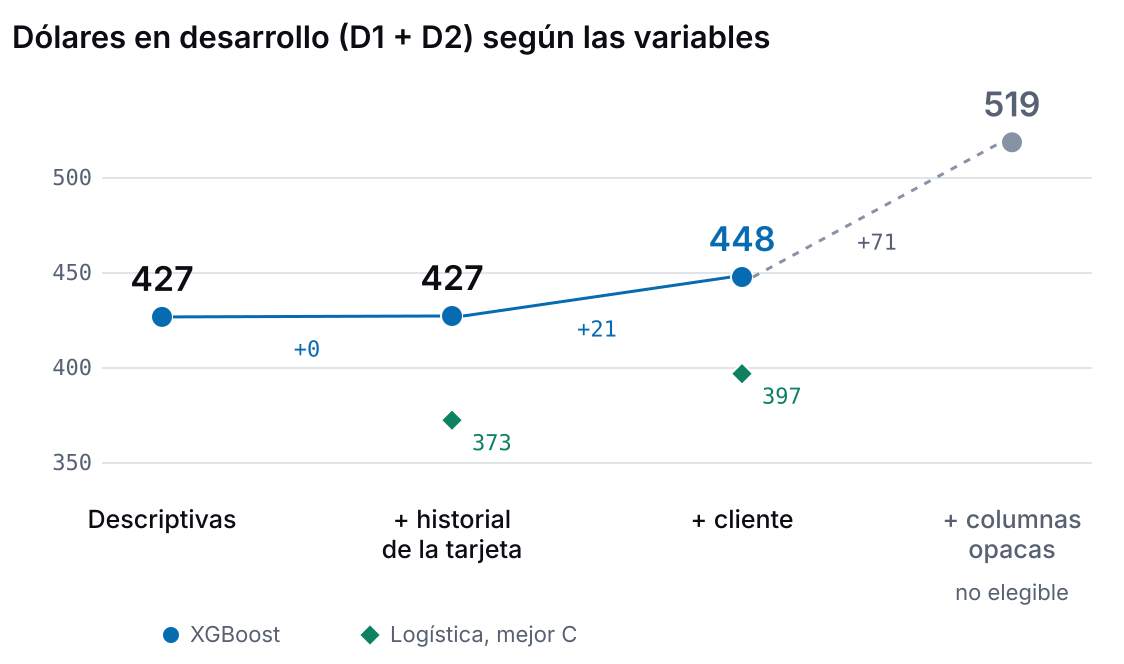

In [31]:
fig("ablacion")

**Por qué F3.** Cada bloque de variables nuevas sube el dinero: el historial por tarjeta (F2) y el cliente
reconstruido (F3). F4 daría más, pero la descripción pública no dice en qué momento calcula Vesta sus columnas opacas:
podrían usar información posterior al pago. Quedaron fuera antes de la prueba.

**Importancia por permutación en dólares (D2).** Cuánto dinero se pierde al barajar cada grupo de variables.

In [32]:
dg = S["diagnosticos_D2"]
(pd.Series(dg["importancia_usd"]) / 1e3).round(1).sort_values(ascending=False).rename("mil USD que se pierden al barajar").to_frame()

,mil USD que se pierden al barajar
monto y centavos,74.7
coincidencias M1-M9,36.9
dispositivo e identidad,36.8
historial del cliente,34.8
tarjeta,18.3
correo,15.1
producto,2.3
historial de la tarjeta,-1.7
dirección y distancia,-2.3
hora y día,-2.3


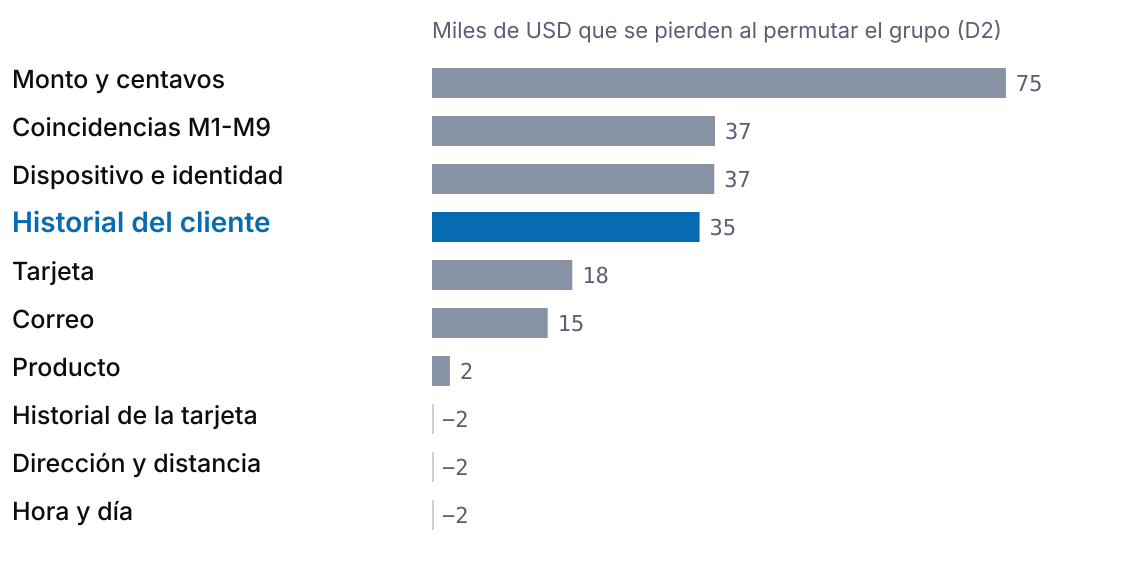

In [33]:
fig("importancia")

**¿Mejores variables? Búsqueda con validación cruzada temporal.** Estudio posterior a la prueba, con los días 1–120
y un diseño registrado antes de correr (`docs/anexo_variables.md`): ocho grupos candidatos, selección hacia adelante en
tres ventanas con origen móvil (un grupo entra si sube el total al menos 1% y mejora en dos de las tres) y un bloque de
confirmación (días 106–120) que la búsqueda no usa.

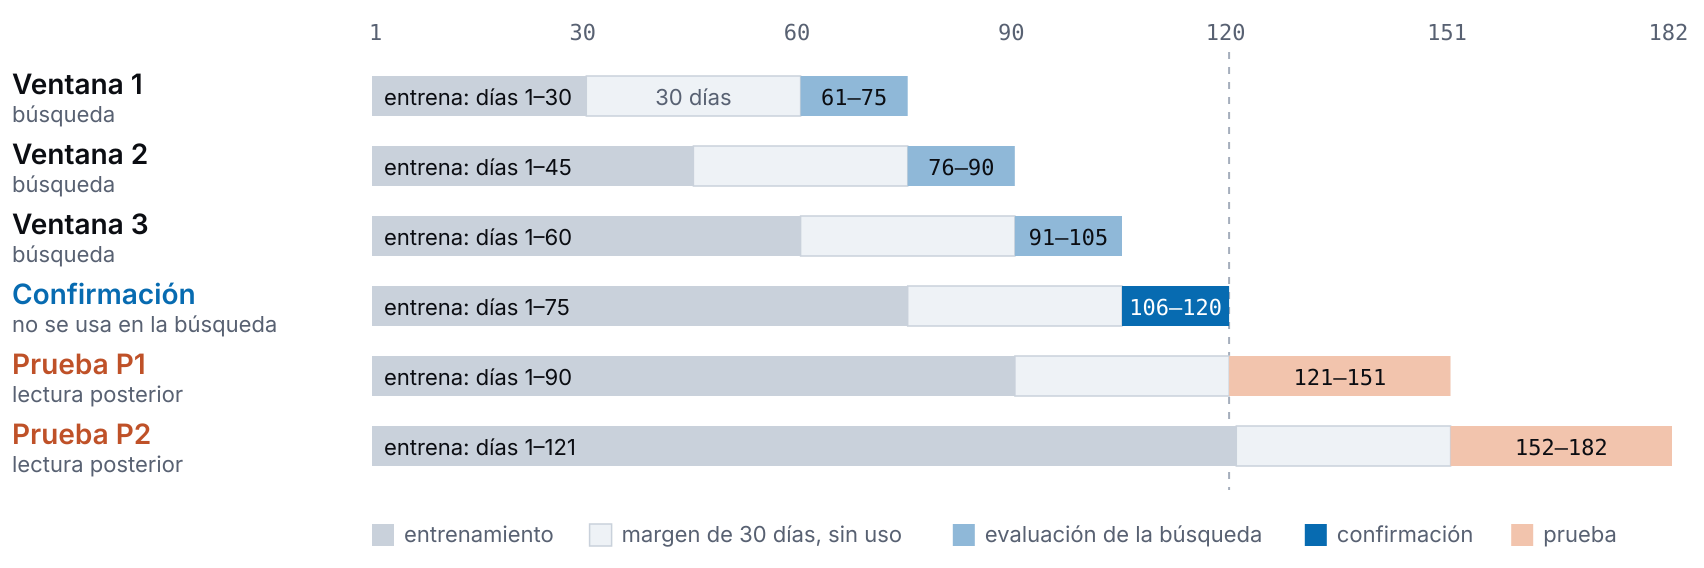

In [34]:
fig("validacion")

In [35]:
rd = pd.DataFrame([{"ronda": r["ronda"], **{g: f"{v['ganancia'] * 100:+.1f}% · {v['suben']} de 3" for g, v in r["pruebas"].items()},
                    "acepta": r["mejor"] if r["acepta"] else "ninguno"} for r in VA["rondas"]]).set_index("ronda").T
print(f"Aceptados: {', '.join(VA['elegidos'])} · ventanas de búsqueda: {VA['base_F3']['total_usd'] / 1e3:,.1f} → "
      f"{VA['final_interno']['total_usd'] / 1e3:,.1f} mil USD ({pc(VA['final_interno']['total_usd'] / VA['base_F3']['total_usd'] - 1)})")
rd.fillna("—")

Aceptados: perfil, novedad, uid_fino · ventanas de búsqueda: 296.0 → 314.1 mil USD (+6.1%)


ronda,1,2,3,4
ventanas,+0.4% · 1 de 3,-0.4% · 1 de 3,-1.1% · 1 de 3,-2.0% · 0 de 3
perfil,+2.5% · 2 de 3,—,—,—
novedad,+0.2% · 2 de 3,+1.9% · 2 de 3,—,—
compartido,+1.1% · 2 de 3,+1.2% · 3 de 3,-2.5% · 1 de 3,-6.1% · 0 de 3
texto,+1.1% · 2 de 3,+0.5% · 1 de 3,-1.7% · 1 de 3,-2.4% · 1 de 3
monto_fino,+1.0% · 2 de 3,+0.6% · 2 de 3,+0.2% · 2 de 3,-4.8% · 1 de 3
frecuencia,-4.2% · 1 de 3,-2.9% · 2 de 3,-6.5% · 0 de 3,-6.0% · 0 de 3
uid_fino,-0.4% · 1 de 3,-1.6% · 1 de 3,+1.6% · 3 de 3,—
acepta,perfil,novedad,uid_fino,ninguno


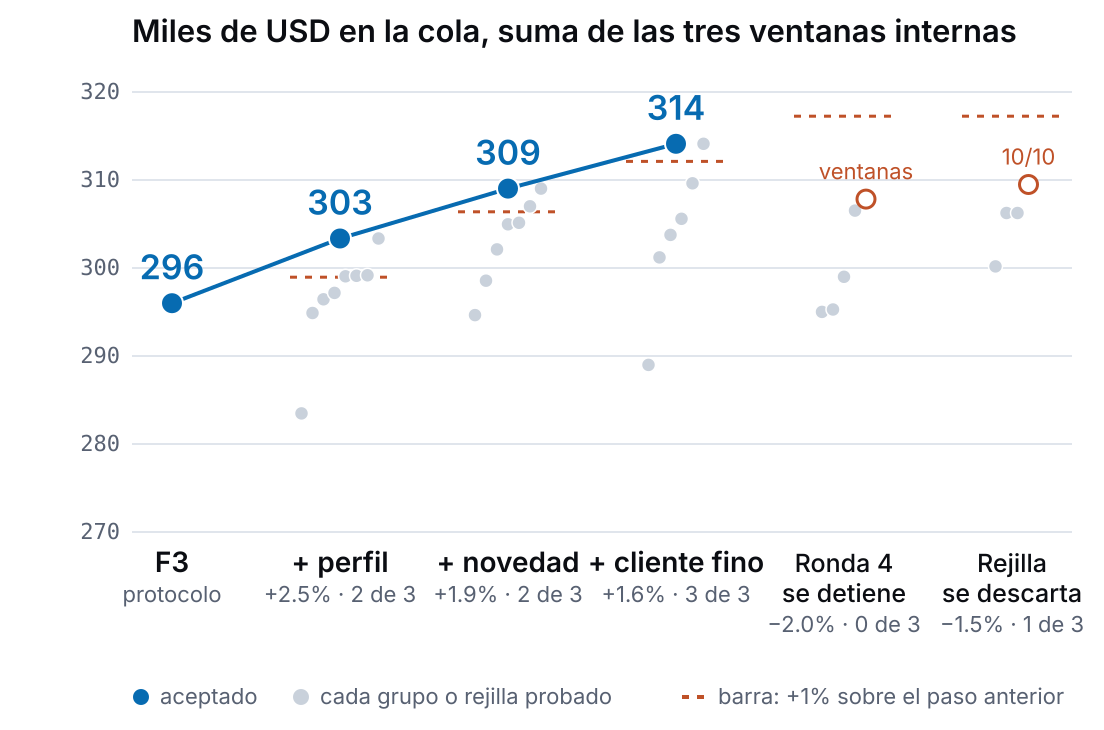

In [36]:
fig("escalada")

**Confirmación, recalculada aquí** desde los puntajes guardados de los días 106–120.

In [37]:
cf = pd.read_parquet(PROCESADOS / "variables_confirmacion.parquet")
d_, y_, m_ = cf["dia"].to_numpy(), cf["fraude"].to_numpy(), cf["monto"].to_numpy()
usd_c = {n: dinero(cf[n].to_numpy() * m_, d_, y_, m_, K) for n in ("F3", "elegido", "con_etiquetas", "logit_F3", "logit_elegido", "regla")}
assert max(abs(usd_c[n] - VA["confirmacion_resultados"]["usd"][n]) for n in usd_c) < 0.01
cc6 = VA["confirmacion_resultados"]["contrastes"]
ETIQ = {"F3": "XGBoost con F3", "elegido": "XGBoost con variables nuevas", "con_etiquetas": "con historial de contracargos (cota)",
        "logit_F3": "logística con F3", "logit_elegido": "logística con variables nuevas", "regla": "mejor regla"}
display(pd.DataFrame({"mil USD, días 106–120": {ETIQ[n]: mil(v) for n, v in usd_c.items()}}))
pd.DataFrame({"contraste": ["variables nuevas contra F3", "logística: nuevas contra F3", "historial de contracargos contra variables nuevas"],
              "ventaja": [pc(cc6[k]["rel"]) for k in ("elegido_vs_F3", "logit_elegido_vs_logit_F3", "con_etiquetas_vs_elegido")],
              "IC 95%": [ic(cc6[k]["rel_ic95"]) for k in ("elegido_vs_F3", "logit_elegido_vs_logit_F3", "con_etiquetas_vs_elegido")]}).set_index("contraste")

,"mil USD, días 106–120"
XGBoost con F3,167.3
XGBoost con variables nuevas,158.4
con historial de contracargos (cota),177.9
logística con F3,163.5
logística con variables nuevas,165.1
mejor regla,139.0


,ventaja,IC 95%
contraste,,
variables nuevas contra F3,-5.3%,-9.6% a -1.1%
logística: nuevas contra F3,+1.0%,-3.3% a +5.3%
historial de contracargos contra variables nuevas,+12.2%,+7.1% a +17.9%


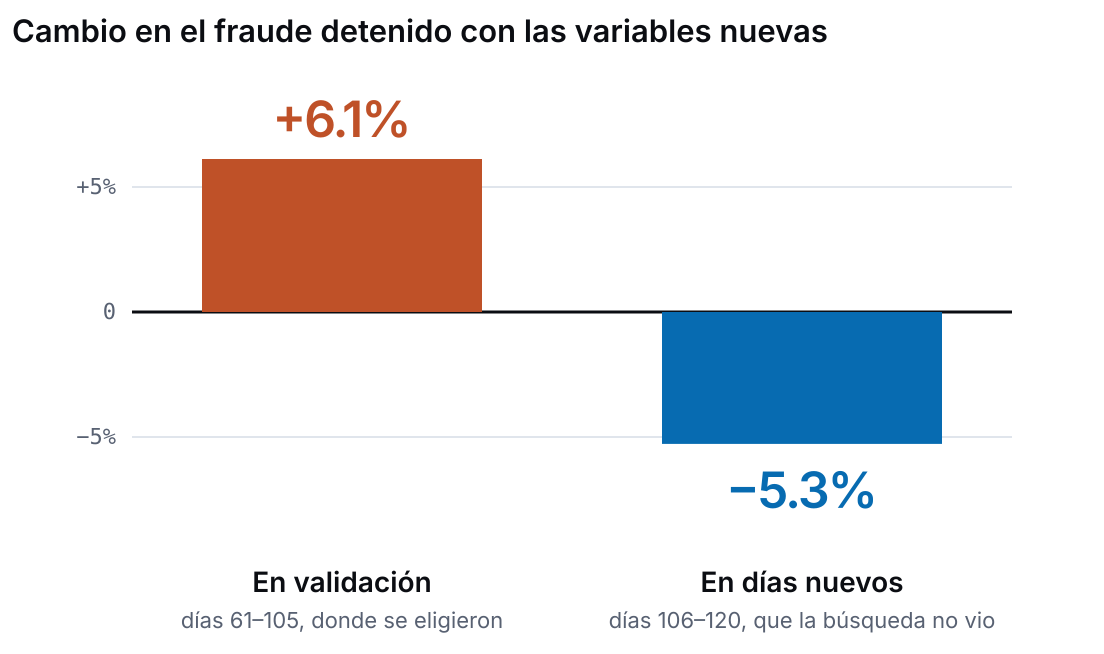

**Decisión: F3 se mantiene.** En las ventanas de búsqueda, los grupos aceptados suben el dinero
+6.1%, pero esas ventanas son las mismas que los eligieron. En los días de
confirmación, el modelo con variables nuevas lleva -5.3% contra F3 (IC 95%: -9.6% a -1.1%): la ganancia no se repite en días
nuevos. Es sobreajuste a la validación.

In [38]:
fig("espejismo")
e = cc6["elegido_vs_F3"]
Markdown(f'''**Decisión: F3 se mantiene.** En las ventanas de búsqueda, los grupos aceptados suben el dinero
{pc(VA['final_interno']['total_usd'] / VA['base_F3']['total_usd'] - 1)}, pero esas ventanas son las mismas que los eligieron. En los días de
confirmación, el modelo con variables nuevas lleva {pc(e['rel'])} contra F3 (IC 95%: {ic(e['rel_ic95'])}): la ganancia no se repite en días
nuevos. Es sobreajuste a la validación.''')

## 4. Modelado

### 4.1 Selección de algoritmos

| Familia | Políticas | Por qué entra |
|---|---|---|
| Reglas de negocio | Mayor monto; tasa histórica suavizada × monto por tarjeta, segmento, correo, producto × decil de monto y velocidad | Representan la práctica actual: transparentes y sin modelo |
| Lineal | Logística L2 con cinco valores de C | Base aprendida con la misma información; interpretable |
| Árbol | CART de profundidad 3 | Reglas legibles aprendidas de los datos |
| Ensambles de árboles | Bosque aleatorio, XGBoost, XGBoost ponderado por monto, ensamble XGBoost + bosque | Interacciones no lineales, faltantes y escalas distintas sin supuestos; lo más fuerte en datos tabulares |
| Red neuronal | MLP con capas de 64 y 32 | Otra forma no lineal, para comparar |
| Anomalías | Bosque de aislamiento | No usa la etiqueta: ¿basta con buscar pagos raros? |

Todas ordenan la cola por **probabilidad × monto** y se evalúan con el mismo cupo de 60. Los hiperparámetros se
fijaron antes del torneo (`src/revisar/politicas.py`):

In [39]:
hp = {"XGBoost": XGB, "Bosque aleatorio": RF, "Árbol CART": CART, "Red MLP": MLP, "Bosque de aislamiento": ISO,
      "Logística L2": {"C": CS, "max_iter": 3000}}
pd.DataFrame({"hiperparámetros": {m: ", ".join(f"{k}={v}" for k, v in d.items() if k not in ("n_jobs", "random_state"))
                                  for m, d in hp.items()}})

,hiperparámetros
XGBoost,"n_estimators=600, max_depth=8, learning_rate=0.05, subsample=0.8, colsample_bytree=0.5, tree_method=hist, eval_metric=logloss"
Bosque aleatorio,"n_estimators=300, min_samples_leaf=5, max_features=0.3"
Árbol CART,"max_depth=3, min_samples_leaf=200"
Red MLP,"hidden_layer_sizes=(64, 32), alpha=0.0001, batch_size=512, learning_rate_init=0.001, max_iter=30, early_stopping=True, validation_fraction=0.1, n_iter_no_change=4"
Bosque de aislamiento,n_estimators=200
Logística L2,"C=(0.001, 0.003, 0.01, 0.03, 0.1), max_iter=3000"


In [40]:
codigo(_tasa, reglas, modelos, puntaje)

`src/revisar/politicas.py` · `_tasa`

```python
def _tasa(ktr: pd.Series, ytr: np.ndarray, kte: pd.Series) -> np.ndarray:
    prior = ytr.mean()
    g = pd.DataFrame({"k": ktr.to_numpy(), "y": ytr}).groupby("k")["y"].agg(["sum", "count"])
    tasa = (g["sum"] + SUAVIZADO * prior) / (g["count"] + SUAVIZADO)
    return kte.map(tasa).fillna(prior).to_numpy(float)
```

`src/revisar/politicas.py` · `reglas`

```python
def reglas(tr: pd.DataFrame, te: pd.DataFrame) -> dict[str, np.ndarray]:
    """Tasa de fraude histórica (suavizada) de cada regla; el puntaje es tasa × monto. R_monto: tasa constante."""
    ytr = tr["fraude"].to_numpy()
    out = {"R_monto": np.ones(len(te))}
    for nombre, campos in (("R_tarjeta", ["card1"]), ("R_segmento", ["ProductCD", "card4", "card6", "DeviceType"]),
                           ("R_correo", ["P_emaildomain", "ProductCD"])):
        out[nombre] = _tasa(_clave(tr, campos), ytr, _clave(te, campos))
    cortes = list(np.quantile(tr["TransactionAmt"], np.linspace(0, 1, 11)[1:-1]))
    dec = lambda d: d["ProductCD"] + "|" + _tramos(d["TransactionAmt"], cortes)  # noqa: E731
    out["R_tabla"] = _tasa(dec(tr), ytr, dec(te))
    vel = lambda d: (d["ProductCD"] + "|" + _tramos(d["h_tarjeta_dir_previos"], [0.5, 2.5, 9.5])  # noqa: E731
                     + "|" + _tramos(d["h_tarjeta_dir_ultimo_dia"], [0.5, 1.5]))
    out["R_velocidad"] = _tasa(vel(tr), ytr, vel(te))
    return out
```

`src/revisar/politicas.py` · `modelos`

```python
def modelos(tr: pd.DataFrame, te: pd.DataFrame, conjunto: str, cuales: tuple[str, ...]) -> dict[str, np.ndarray]:
    """Probabilidad de fraude de cada pago de te. ISO devuelve el percentil de rareza (no es probabilidad)."""
    dis = Diseno(tr, conjunto)
    y = tr["fraude"].to_numpy()
    A, B = dis.matriz(tr), dis.matriz(te)
    out = {}
    lentos = [(f"LOGIT_C{c}", delayed(_logit)(c, A, y, B)) for c in CS if "LOGIT" in cuales]
    if "MLP" in cuales:
        lentos.append(("MLP", delayed(_mlp)(A, y, B)))
    if lentos:
        res = Parallel(n_jobs=len(lentos), backend="loky")(t for _, t in lentos)
        out.update({n: p for (n, _), p in zip(lentos, res)})
    if {"XGB", "ENS"} & set(cuales):
        out["XGB"] = xgb.XGBClassifier(**XGB).fit(A, y).predict_proba(B)[:, 1]
    if "XGB_pond" in cuales:
        w = tr["TransactionAmt"].to_numpy(float)
        out["XGB_pond"] = xgb.XGBClassifier(**XGB).fit(A, y, sample_weight=w / w.mean()).predict_proba(B)[:, 1]
    if {"RF", "CART", "ISO", "ENS"} & set(cuales):
        Na, Nb = dis.nativa(tr), dis.nativa(te)
        if {"RF", "ENS"} & set(cuales):
            out["RF"] = RandomForestClassifier(**RF).fit(Na, y).predict_proba(Nb)[:, 1]
        if "CART" in cuales:
            out["CART"] = DecisionTreeClassifier(**CART).fit(Na, y).predict_proba(Nb)[:, 1]
        if "ISO" in cuales:
            rareza = -IsolationForest(**ISO).fit(Na).score_samples(Nb)
            out["ISO"] = pd.Series(rareza).rank(pct=True).to_numpy()
    if "ENS" in cuales:
        out["ENS"] = (out["XGB"] + out["RF"]) / 2
    return {k: v for k, v in out.items() if k in cuales or k.startswith("LOGIT")}
```

`src/revisar/politicas.py` · `puntaje`

```python
def puntaje(nombre: str, p: np.ndarray, monto: np.ndarray, modo: str = "p_x_monto") -> np.ndarray:
    """Orden de la cola: probabilidad × monto (por defecto) o solo probabilidad. R_monto ordena por monto."""
    if nombre == "R_monto":
        return monto.copy()
    return p * monto if modo == "p_x_monto" else p.copy()
```

**El torneo de desarrollo.** Dos bloques: D1 (días 61–90, entrena con 1–30) y D2 (días 91–120, entrena con
1–60). La regla de selección se escribió antes de correrlo (`docs/criterio_desarrollo.md`): gana el modelo flexible
con más dólares en D1 + D2 (un ensamble necesita 1% más que el mejor modelo solo), y solo si supera a la mejor
logística en los dos bloques. Aquí se recalcula desde los dólares de cada política.

In [41]:
display((dv / 1e3).round(1).sort_values("total", ascending=False).rename(columns=lambda c: f"{c} (mil USD)").head(15))
elegibles = [f"{f}|{c}" for f in FLEXIBLES for c in ("F2", "F3")]
mejor = dv.loc[elegibles, "total"].idxmax()
if mejor.startswith("ENS"):
    unico = dv.loc[[e for e in elegibles if not e.startswith("ENS")], "total"].idxmax()
    if dv.loc[mejor, "total"] < 1.01 * dv.loc[unico, "total"]:
        mejor = unico
logit = dv.loc[[f"LOGIT_C{c}|{f}" for c in CS for f in ("F2", "F3")], "total"].idxmax()
regla = dv.loc[list(REGLAS), "total"].idxmax()
supera = all(dv.loc[mejor, b] > dv.loc[logit, b] for b in ("D1", "D2"))
final = mejor if supera else logit
assert (final, logit, regla, supera) == (S["final"], S["mejor_logit"], S["mejor_regla"], S["supera_lineal_en_ambos"])
print(f"Regla recalculada: modelo final {final}, mejor logística {logit}, mejor regla {regla}; "
      f"supera a la logística en ambos bloques: {supera}")

,D1 (mil USD),D2 (mil USD),total (mil USD)
XGB|F4,219.7,299.0,518.8
XGB|F3,183.7,264.2,447.9
ENS|F3,164.6,273.0,437.6
ENS|F2,159.2,271.9,431.1
XGB|F2,171.0,256.4,427.4
XGB|F1,172.2,254.7,426.9
XGB_pond|F3,168.6,244.3,413.0
RF|F3,142.9,255.0,397.9
LOGIT_C0.003|F3,142.8,254.2,397.0
RF|F2,138.4,254.5,392.8


Regla recalculada: modelo final XGB|F3, mejor logística LOGIT_C0.003|F3, mejor regla R_segmento; supera a la logística en ambos bloques: True


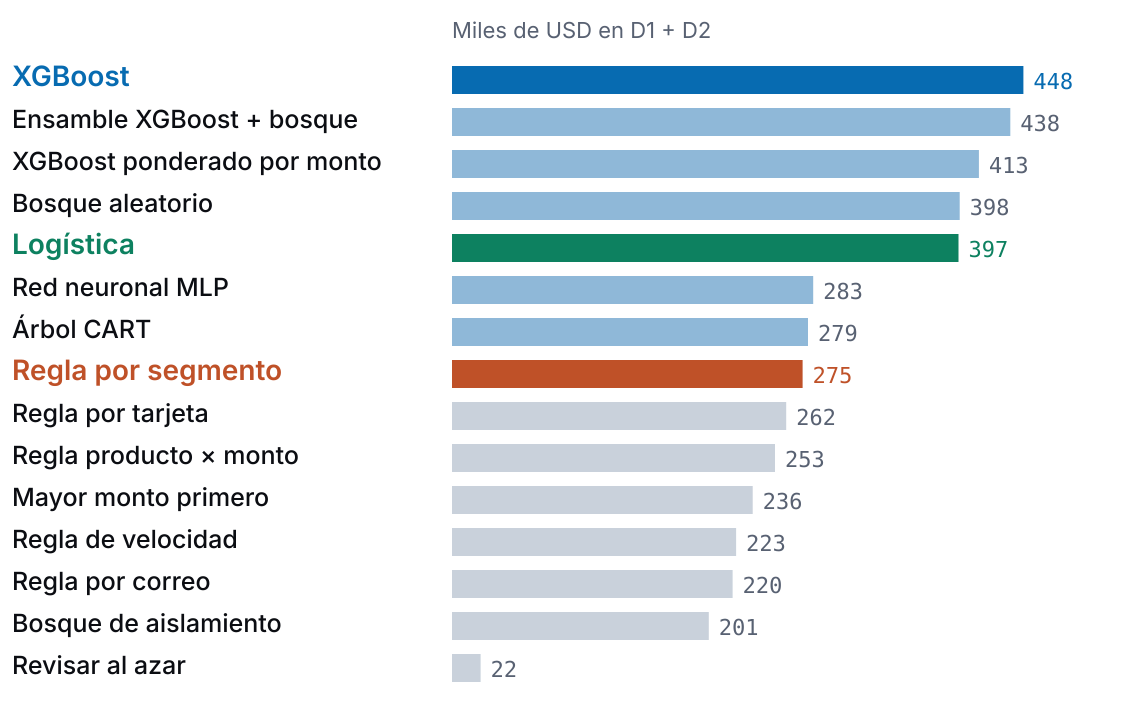

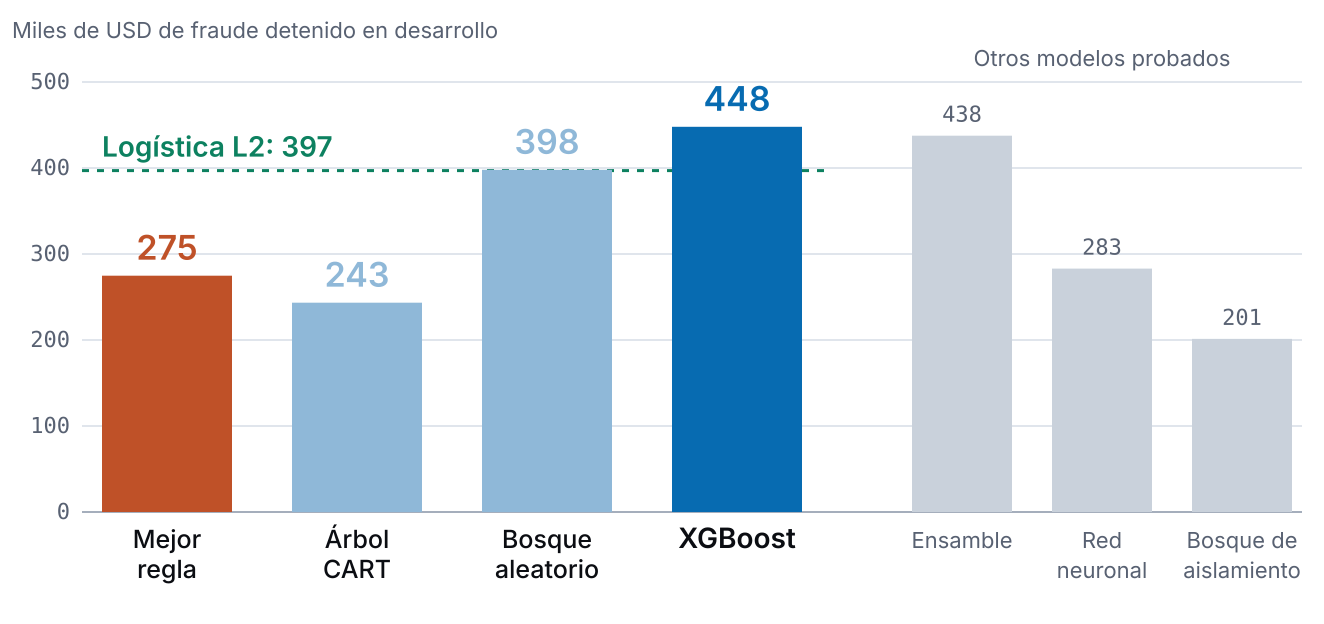

In [42]:
fig("torneo", "modelos")

**Por qué XGBoost.** Es el que más dinero detiene en los dos bloques. El bosque de aislamiento, que no usa la
etiqueta, queda muy abajo: el fraude de estos datos no es solo "lo raro". **Pruebas de cordura en D2:**

In [43]:
pd.Series({"Modelo": dg["cordura"]["base"], "El mismo modelo con etiquetas barajadas": dg["cordura"]["etiquetas_barajadas"],
           "Revisar al azar (esperado)": dg["cordura"]["azar_esperado"], "Árbol de profundidad 3": dg["arbol"]["usd_D2"]}).div(1e3).round(1).rename("mil USD en D2").to_frame()

,mil USD en D2
Modelo,264.2
El mismo modelo con etiquetas barajadas,117.3
Revisar al azar (esperado),12.3
Árbol de profundidad 3,159.9


Con las etiquetas barajadas, la probabilidad queda casi constante y la cola se ordena prácticamente por monto: eso
explica lo que todavía detiene. La diferencia con el modelo real es lo que aprende de las etiquetas.

### 4.2 Entrenamiento: partición en el tiempo

La partición no es al azar. Los pagos se ordenan en el tiempo: cada bloque entrena con días anteriores y evalúa días
posteriores, como en operación. Entre el último día de entrenamiento y el primero evaluado hay **30 días de margen**:
es lo que tarda en llegar el contracargo, así que al entrenar no se conocería la etiqueta de los pagos más recientes.
Una partición al azar pondría pagos de un mismo cliente en los dos lados y sobrestimaría el desempeño.

In [44]:
codigo(bloque)

`src/revisar/datos.py` · `bloque`

```python
def bloque(df: pd.DataFrame, inicio: int, fin: int, margen: int = 30) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Entrenamiento (días < inicio - margen) y evaluación (días inicio a fin, inclusive)."""
    return (df[df["dia"] < inicio - margen].reset_index(drop=True),
            df[(df["dia"] >= inicio) & (df["dia"] <= fin)].reset_index(drop=True))
```

In [45]:
t0 = time.time()
todo = cargar(183)                                 # los 182 días: la prueba ya se corrió, aquí se reproduce
print(f"Días {todo['dia'].min()}–{todo['dia'].max()}: {len(todo):,} pagos, cargados en {time.time() - t0:.0f} s")
PART = {"D1": (61, 90), "D2": (91, 120), **P}
filas = {}
for b, (ini, fin) in PART.items():
    tr, te = bloque(todo, ini, fin)
    info = S["info_bloques"][b] if b in S["info_bloques"] else R[b]
    assert len(tr) == info["entrenamiento"] and len(te) == info.get("evaluacion", info.get("pagos"))
    filas[b] = {"uso": "desarrollo: elegir" if b[0] == "D" else "prueba: una sola corrida", "entrena con días": f"{tr['dia'].min()}–{tr['dia'].max()}",
                "evalúa días": f"{ini}–{fin}", "pagos de entrenamiento": f"{len(tr):,}", "pagos evaluados": f"{len(te):,}",
                "tasa de fraude evaluada": f"{te['fraude'].mean():.2%}", "fraude evaluado (mil USD)": mil((te["fraude"] * te["TransactionAmt"]).sum())}
pd.DataFrame(filas).T

Días 1–182: 590,540 pagos, cargados en 11 s


,uso,entrena con días,evalúa días,pagos de entrenamiento,pagos evaluados,tasa de fraude evaluada,fraude evaluado (mil USD)
D1,desarrollo: elegir,1–30,61–90,"134,339","92,189",4.04%,523.6
D2,desarrollo: elegir,1–60,91–120,"223,738","98,615",3.95%,658.9
P1,prueba: una sola corrida,1–90,121–151,"315,927","86,672",3.40%,472.7
P2,prueba: una sola corrida,1–121,152–182,"417,559","89,326",3.49%,477.4


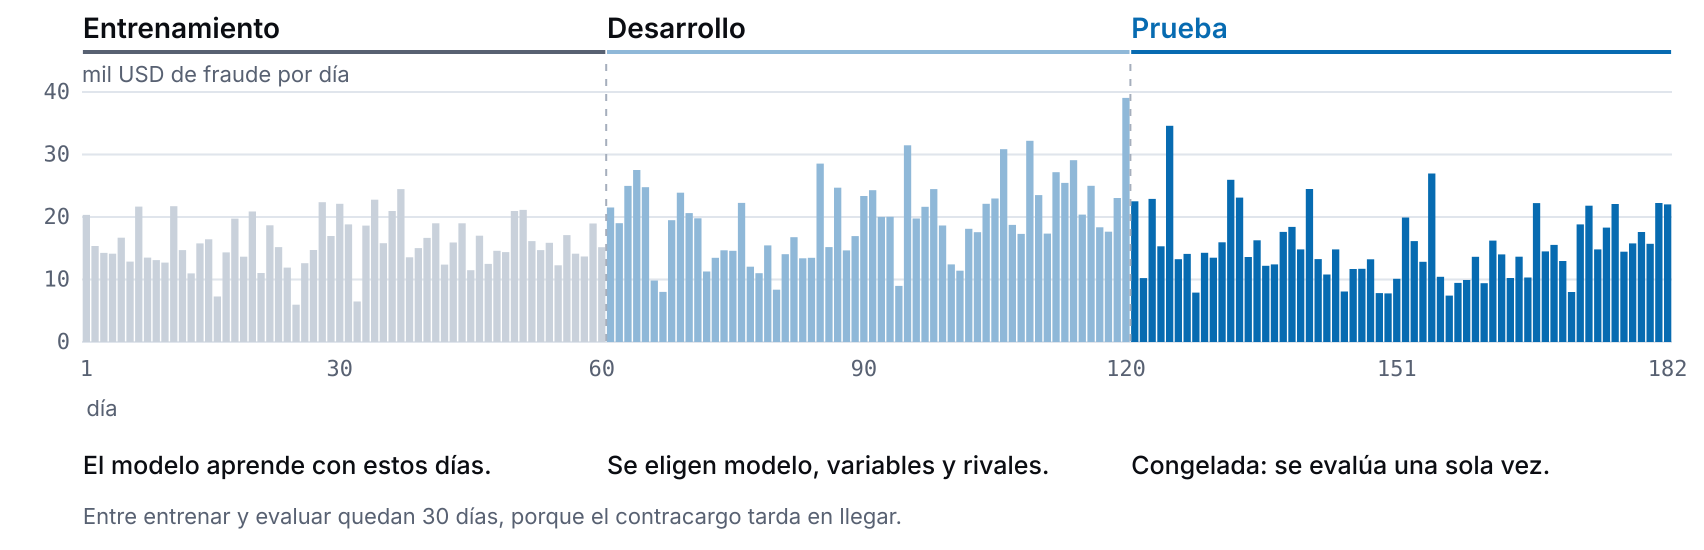

In [46]:
fig("calendario")

**¿Se usan todos los datos?** Sí, con dos límites que pone el problema y no el modelo. Al entrenar solo se puede
usar lo que ya tiene etiqueta: cada modelo usa **todos** los pagos con al menos 30 días de antigüedad, y nada más.
Y quedan fuera las columnas opacas de Vesta, porque no se sabe en qué momento se calculan.

In [47]:
for b, (ini, fin) in PART.items():
    tr, _ = bloque(todo, ini, fin)
    assert len(tr) == int((todo["dia"] < ini - 30).sum()), "el entrenamiento debe tener todos los pagos ya etiquetados"
tr_p2, _ = bloque(todo, *P["P2"])
f3, f4 = (dv.loc[f"XGB|{c}", "total"] for c in ("F3", "F4"))
pd.Series({"Pagos en el archivo": f"{meta.num_rows:,}",
           "Pagos con los que entrena el modelo de P2 (todos los de los días 1–121)": f"{len(tr_p2):,}",
           "Pagos evaluados en la prueba (días 121–182)": f"{sum(R[x]['pagos'] for x in P):,}",
           f"Columnas en el archivo ({vacias.num_columns} vacías)": meta.num_columns,
           "Columnas crudas que usa el modelo (con TransactionDT, de la que salen la hora y el historial)": len(usa) + 1,
           "Variables del modelo final (F3)": len(CONJUNTOS["F3"][0]) + len(CONJUNTOS["F3"][1]),
           "Columnas opacas de Vesta que no usa": len(VESTA),
           "Dinero en desarrollo si se agregaran (F4 contra F3)": pc(f4 / f3 - 1)}).to_frame("valor")

,valor
Pagos en el archivo,"590,540"
Pagos con los que entrena el modelo de P2 (todos los de los días 1–121),"417,559"
Pagos evaluados en la prueba (días 121–182),"175,998"
Columnas en el archivo (23 vacías),456
"Columnas crudas que usa el modelo (con TransactionDT, de la que salen la hora y el historial)",65
Variables del modelo final (F3),93
Columnas opacas de Vesta que no usa,367
Dinero en desarrollo si se agregaran (F4 contra F3),+15.8%


Las columnas opacas subirían el dinero en desarrollo, pero si alguna se calcula con información posterior al pago, ese
dinero no existiría en operación. Agregarlas ahora, después de ver la prueba, además invalidaría la evaluación: es una
mejora para probar en el piloto, con días nuevos y después de preguntarle a Vesta cuándo se calculan.

**El modelo final, entrenado aquí.** El mismo código de la prueba entrena XGBoost con F3 sobre los días 1–90 y arma
la cola de P1 (días 121–151), junto con la mejor regla. Los resultados oficiales de la prueba, con sus intervalos, son
los de la sección 5.

In [48]:
t0 = time.time()
tr, te = bloque(todo, *P["P1"])
p_vivo = modelos(tr, te, "F3", ("XGB",))["XGB"]
r_vivo = reglas(tr, te)[REGLA]
m_, d_, y_ = te["TransactionAmt"].to_numpy(float), te["dia"].to_numpy(), te["fraude"].to_numpy()
print(f"XGBoost con F3 entrenado con {len(tr):,} pagos (días {tr['dia'].min()}–{tr['dia'].max()}) y aplicado a "
      f"{len(te):,} pagos de P1, en {time.time() - t0:.0f} s")
aqui, usd_aqui = {}, {}
for n, p in ((FINAL, p_vivo), (REGLA, r_vivo)):
    mz = matriz(p * m_, d_, y_, m_, K)
    usd_aqui[n] = mz["revisado_fraude"]["usd"]
    aqui[NOMBRE[n]] = {"fraude detenido (mil USD)": mil(usd_aqui[n]), "parte del fraude de P1": f"{mz['parte_usd_fraude']:.0%}",
                       "fraudes en la cola": f"{mz['revisado_fraude']['pagos']:,}", "precisión de la cola": f"{mz['precision']:.1%}",
                       "AUC": round(roc_auc_score(y_, p), 3)}
ventaja_aqui = usd_aqui[FINAL] / usd_aqui[REGLA] - 1
assert ventaja_aqui > 0.15, "el modelo entrenado aquí debe ganarle a la regla con holgura"
print(f"Ventaja del modelo sobre la regla en P1: {pc(ventaja_aqui)}")
pd.DataFrame(aqui).T

XGBoost con F3 entrenado con 315,927 pagos (días 1–90) y aplicado a 86,672 pagos de P1, en 34 s
Ventaja del modelo sobre la regla en P1: +32.9%


,fraude detenido (mil USD),parte del fraude de P1,fraudes en la cola,precisión de la cola,AUC
Modelo: XGBoost con F3,216.1,46%,614,33.0%,0.872
Mejor regla: tasa por segmento × monto,162.6,34%,218,11.7%,0.727


### 4.3 Optimización de hiperparámetros

Los hiperparámetros se eligen **por dólares en desarrollo**, no por AUC ni por pérdida logarítmica. Tres decisiones:
la regularización de la logística, el número de árboles de XGBoost (con parada temprana) y su profundidad (rejilla
con validación cruzada temporal).

**Regularización de la logística (C).**

In [49]:
rg = pd.DataFrame(L["regularizacion"])
rg.assign(usd=(rg["usd"] / 1e3).round(1)).pivot(index="C", columns="conjunto", values=["usd", "auc"]).round(3).rename(columns={"usd": "mil USD", "auc": "AUC"})

mil USD           AUC       
conjunto      F2     F3     F2     F3
C                                    
0.001      369.6  382.8  0.799  0.803
0.003      372.5  397.0  0.803  0.807
0.010      366.1  388.7  0.806  0.809
0.030      362.1  377.0  0.805  0.807
0.100      345.0  357.4  0.800  0.801

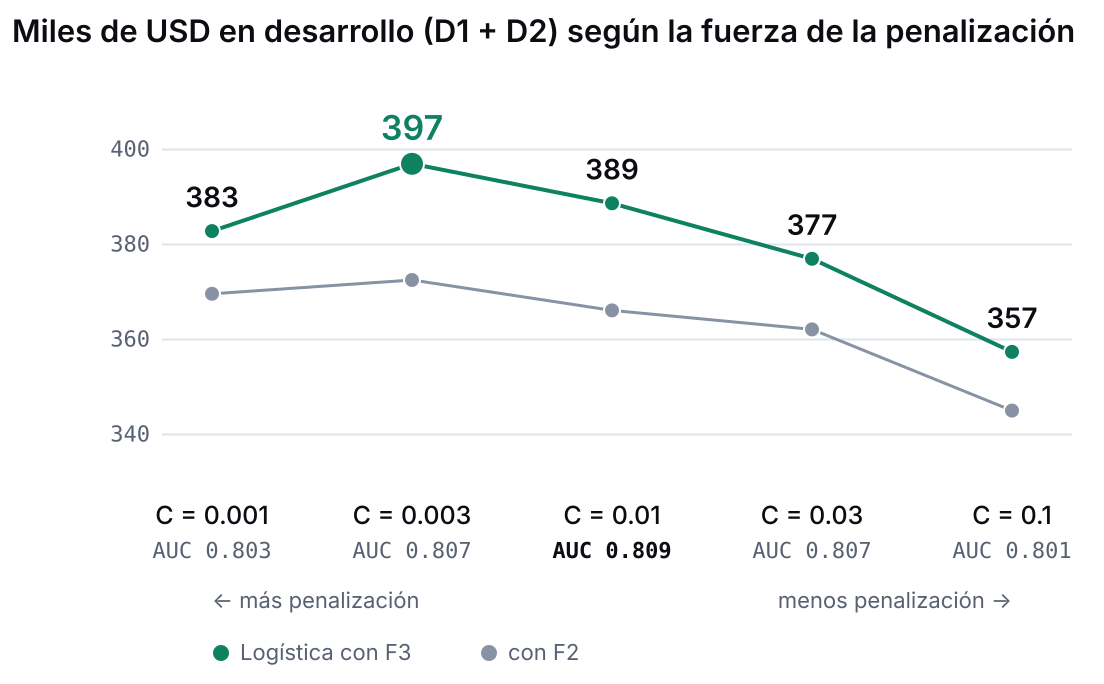

In [50]:
fig("regularizacion")

C = 0.003 da más dinero aunque no tenga el AUC más alto: el criterio de selección es el dinero.

**XGBoost: rejilla de profundidad con parada temprana.** Cuatro combinaciones, cada una con parada temprana (hasta 4,000
árboles; se detiene tras 150 sin mejorar en 10 días de validación), medidas en las tres ventanas de la búsqueda de 3.3.
Se adopta solo si supera a los hiperparámetros del protocolo por 1% y en dos de tres ventanas.

In [51]:
rj = pd.DataFrame([{**r["params"], "mil USD (3 ventanas)": mil(r["total_usd"]), "AUC": round(r["auc"], 3),
                    "árboles elegidos por ventana": " / ".join(str(v) for v in r["arboles"].values())} for r in VA["rejilla"]])
hpx = VA["hiperparametros"]
print(f"Protocolo: {VA['protocolo_xgb']}. Mejor combinación de la rejilla: {pc(hpx['ganancia'])} contra el protocolo, "
      f"mejora en {hpx['suben']} de 3 ventanas → {'se adopta' if hpx['adopta'] else 'se quedan los del protocolo'}.")
rj

Protocolo: {'n_estimators': 600, 'max_depth': 8, 'learning_rate': 0.05}. Mejor combinación de la rejilla: -1.5% contra el protocolo, mejora en 1 de 3 ventanas → se quedan los del protocolo.


,max_depth,min_child_weight,mil USD (3 ventanas),AUC,árboles elegidos por ventana
0,6,1,300.2,0.846,391 / 537 / 785
1,8,1,306.3,0.847,163 / 311 / 618
2,8,10,306.3,0.843,299 / 500 / 632
3,10,10,309.5,0.843,211 / 361 / 480


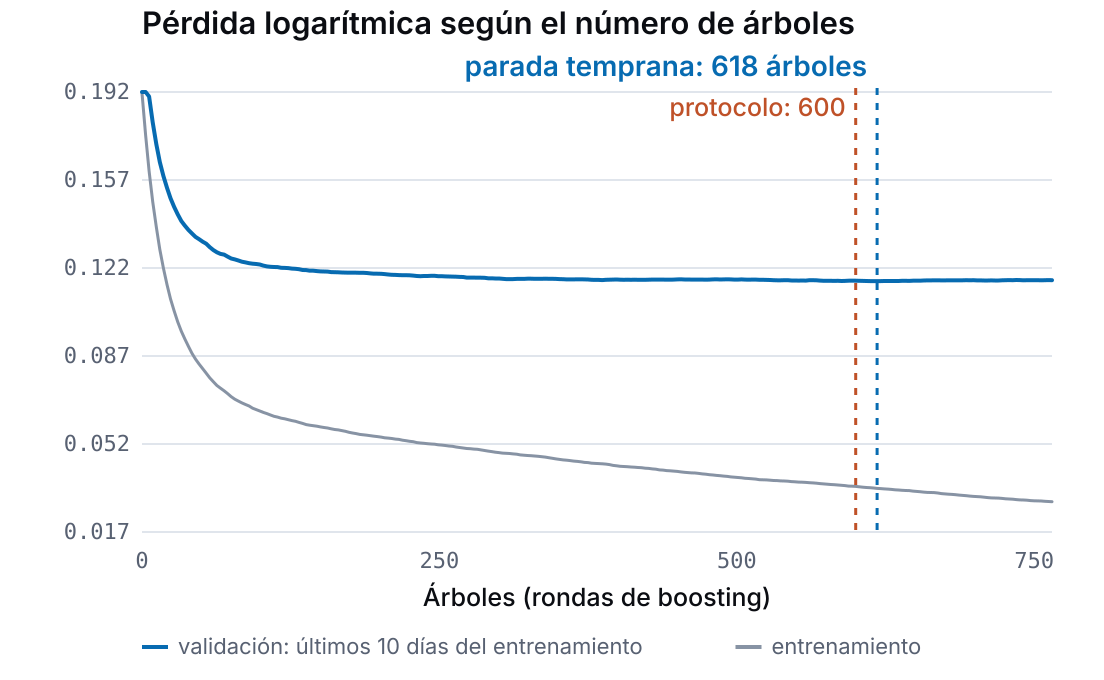

Ventana V3: la pérdida de validación deja de bajar cerca del árbol 618; el protocolo usa 600 árboles con tasa de aprendizaje 0.05.


In [52]:
fig("aprendizaje")
ap = VA["aprendizaje"]
print(f"Ventana {ap['ventana']}: la pérdida de validación deja de bajar cerca del árbol {ap['mejor_iteracion']}; "
      f"el protocolo usa {ap['arboles_protocolo']} árboles con tasa de aprendizaje {ap['learning_rate']}.")

Ninguna combinación de la rejilla supera a la del protocolo (600 árboles de profundidad 8), y la parada temprana
llega a un número de árboles parecido: el modelo congelado ya estaba cerca del óptimo. El cupo de 60 no es un
hiperparámetro: lo fija el negocio. La sección 5.2 mide la ventaja con 30 y 120 revisiones.

## 5. Evaluación en los dos meses de prueba

P1: días 121–151 (entrena con 1–90). P2: días 152–182 (entrena con 1–121). Todo quedó congelado antes de leerlos y la
prueba se corrió una vez.

### 5.1 Métricas de desempeño

**Dólares de fraude en la cola, recalculados aquí.** Se toman los puntajes guardados de cada pago y se arma la cola de
60 de cada día con el código congelado de `src/revisar/evaluacion.py`:

In [53]:
codigo(seleccion, dinero)

`src/revisar/evaluacion.py` · `seleccion`

```python
def seleccion(score: np.ndarray, dia: np.ndarray, k: int) -> np.ndarray:
    """Marca los k pagos de mayor puntaje de cada día. Empates: gana el pago anterior en el tiempo."""
    s = np.nan_to_num(np.asarray(score, float), nan=-np.inf)
    orden = np.lexsort((-s, dia))
    d = dia[orden]
    rango = np.arange(len(d)) - np.searchsorted(d, d, side="left")
    marca = np.zeros(len(d), bool)
    marca[orden[rango < k]] = True
    return marca
```

`src/revisar/evaluacion.py` · `dinero`

```python
def dinero(score, dia, y, monto, k) -> float:
    return float(por_dia(score, dia, y, monto, k).sum())
```

In [54]:
PT, SC, vivo = {}, {}, {}
for x in P:
    PT[x] = g = pd.read_parquet(PROCESADOS / f"prueba_puntajes_{x}.parquet")
    dia_, y_, m_ = g["dia"].to_numpy(), g["fraude"].to_numpy(), g["monto"].to_numpy()
    s = {n: puntaje(n.split("|")[0], g[n].to_numpy(), m_) for n in (FINAL, LOGIT, REGLA, "R_monto")}   # probabilidad × monto
    s[PUB] = puntaje(FINAL.split("|")[0], g[FINAL].to_numpy(), m_, "p")       # el mismo modelo, ordenado solo por probabilidad
    s["oraculo"] = y_ * m_
    SC[x] = s
    vivo[x] = {n: dinero(v, dia_, y_, m_, K) for n, v in s.items()}
tab = pd.DataFrame({x: {NOMBRE[n]: v / 1e3 for n, v in vivo[x].items()} for x in P}).round(1)
tab.columns = [f"{x}: mil USD" for x in P]
for x in P:
    tab[f"{x}: parte del oráculo"] = [f"{vivo[x][n] / vivo[x]['oraculo']:.0%}" for n in vivo[x]]
dif = max(abs(vivo[x][n] - R[x]["usd"][n]) for x in P for n in vivo[x])
assert dif < 0.01, "el recálculo no reproduce resultados/prueba.json"
print(f"Diferencia máxima contra resultados/prueba.json: {dif:.6f} USD")
tab

Diferencia máxima contra resultados/prueba.json: 0.000000 USD


,P1: mil USD,P2: mil USD,P1: parte del oráculo,P2: parte del oráculo
Modelo: XGBoost con F3,211.4,226.7,49%,52%
"Mejor logística (C = 0.003, F3)",186.9,185.5,43%,42%
Mejor regla: tasa por segmento × monto,162.6,138.7,38%,32%
Mayor monto primero,131.2,120.9,30%,28%
Solo probabilidad (enfoque de la competencia),100.6,129.9,23%,30%
Oráculo (conoce las etiquetas),432.5,438.6,100%,100%


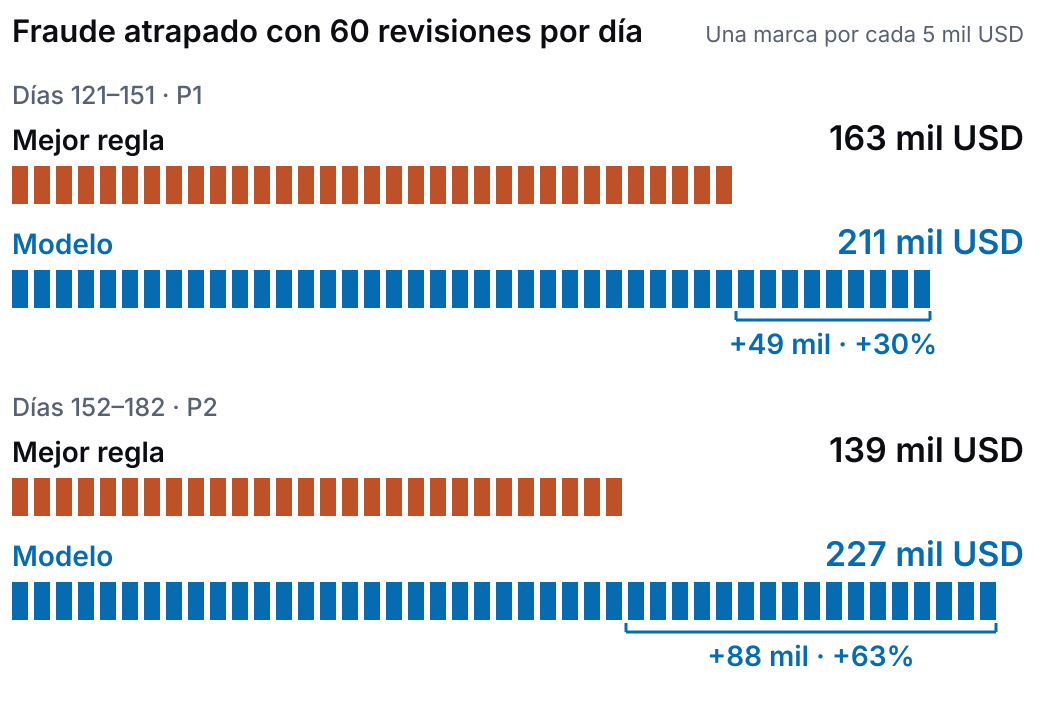

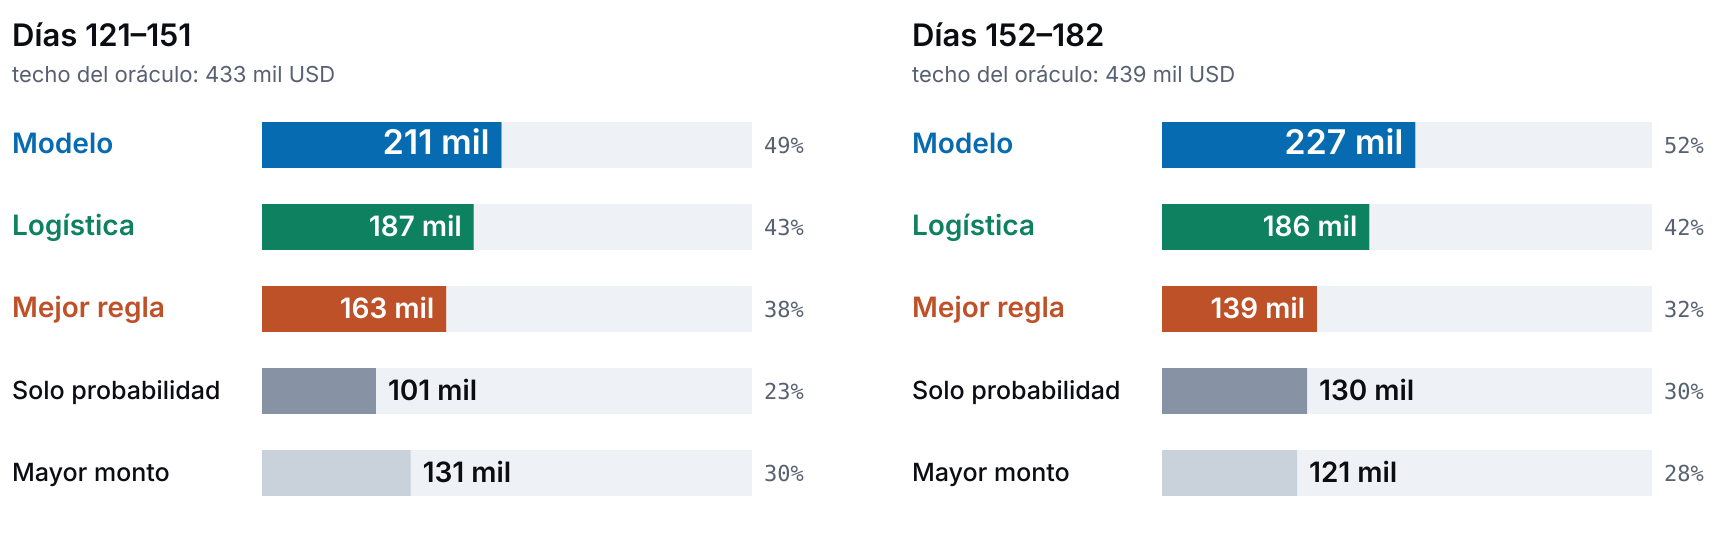

In [55]:
fig("resultado", "prueba")

**Matriz de confusión y métricas de clasificación**, días 121–182, con el cupo de 60 por día: un pago "positivo" es
uno que entra a la cola.

In [56]:
T = pd.concat([PT[x].assign(periodo=x) for x in P], ignore_index=True)
y_t, m_t, d_t = T["fraude"].to_numpy(), T["monto"].to_numpy(), T["dia"].to_numpy()
colas = {"Modelo (probabilidad × monto)": T[FINAL].to_numpy() * m_t, "Solo probabilidad": T[FINAL].to_numpy(),
         "Mejor logística": T[LOGIT].to_numpy() * m_t, "Mejor regla": T[REGLA].to_numpy() * m_t, "Mayor monto primero": m_t}
met, mc = {}, {}
for n, s in colas.items():
    sel = seleccion(s, d_t, K)
    tn, fp, fn, tp = confusion_matrix(y_t, sel).ravel()
    mc[n] = pd.DataFrame([[tp, fp], [fn, tn]], index=["revisado", "no revisado"], columns=["fraude", "legítimo"])
    met[n] = {"exactitud": (tp + tn) / len(y_t), "precisión": tp / (tp + fp), "recall": tp / (tp + fn), "F1": 2 * tp / (2 * tp + fp + fn),
              "AUC-ROC del puntaje": roc_auc_score(y_t, s), "AUC-PR del puntaje": average_precision_score(y_t, s),
              "mil USD en la cola": mil((y_t * m_t)[sel].sum()), "parte del fraude en USD": (y_t * m_t)[sel].sum() / (y_t * m_t).sum()}
met["No revisar nada"] = {"exactitud": 1 - y_t.mean(), "precisión": np.nan, "recall": 0.0, "F1": 0.0, "AUC-ROC del puntaje": 0.5,
                          "AUC-PR del puntaje": y_t.mean(), "mil USD en la cola": 0.0, "parte del fraude en USD": 0.0}
op = CC["operacion"]["modelo"]
assert (mc["Modelo (probabilidad × monto)"].loc["revisado", "fraude"], mc["Modelo (probabilidad × monto)"].loc["revisado", "legítimo"]) == (op["TP"], op["FP"])
print("Matriz de confusión del modelo, en pagos:")
display(mc["Modelo (probabilidad × monto)"])
pd.DataFrame(met).T.round(3)

Matriz de confusión del modelo, en pagos:


,fraude,legítimo
revisado,1116,2604
no revisado,4947,167331


,exactitud,precisión,recall,F1,AUC-ROC del puntaje,AUC-PR del puntaje,mil USD en la cola,parte del fraude en USD
Modelo (probabilidad × monto),0.957,0.300,0.184,0.228,0.816,0.191,438.1,0.461
Solo probabilidad,0.964,0.453,0.278,0.345,0.872,0.340,230.5,0.243
Mejor logística,0.953,0.191,0.117,0.146,0.760,0.110,372.4,0.392
Mejor regla,0.949,0.110,0.067,0.083,0.675,0.071,301.3,0.317
Mayor monto primero,0.947,0.060,0.037,0.046,0.492,0.038,252.2,0.265
No revisar nada,0.966,NaN,0.000,0.000,0.500,0.034,0.0,0.000


**Las métricas de conteo engañan aquí.** No revisar nada tiene la mayor exactitud, porque 96.5% de los pagos es
legítimo. Ordenar solo por probabilidad tiene mejor precisión, recall, F1 y AUC: atrapa más fraudes, pero pequeños. En
dólares, que es lo que el negocio pierde, gana el modelo ordenado por probabilidad × monto.

**Matriz de confusión en dólares**, por mes:

In [57]:
filas = {}
for x in P:
    g, s = PT[x], SC[x]
    for n in (FINAL, LOGIT, REGLA):
        v = matriz(s[n], g["dia"].to_numpy(), g["fraude"].to_numpy(), g["monto"].to_numpy(), K)
        filas[(x, NOMBRE[n])] = {"fraude revisado (mil USD)": mil(v["revisado_fraude"]["usd"]), "fraude que pasa (mil USD)": mil(v["no_revisado_fraude"]["usd"]),
                                 "fraudes revisados": v["revisado_fraude"]["pagos"], "revisiones a legítimos": v["revisado_legitimo"]["pagos"],
                                 "precisión de la cola": f"{v['precision']:.0%}", "parte del fraude del mes": f"{v['parte_usd_fraude']:.0%}"}
pd.DataFrame(filas).T

fraude revisado (mil USD) fraude que pasa (mil USD) fraudes revisados revisiones a legítimos precisión de la cola  \
P1 Modelo: XGBoost con F3                                     211.4                     261.2               605                   1255                  33%   
   Mejor logística (C = 0.003, F3)                            186.9                     285.8               404                   1456                  22%   
   Mejor regla: tasa por segmento × monto                     162.6                     310.1               218                   1642                  12%   
P2 Modelo: XGBoost con F3                                     226.7                     250.7               511                   1349                  27%   
   Mejor logística (C = 0.003, F3)                            185.5                     291.8               308                   1552                  17%   
   Mejor regla: tasa por segmento × monto                     138.7                     338.6               190                   1670                  10%   

                                          parte del fraude del mes  
P1 Modelo: XGBoost con F3                                      45%  
   Mejor logística (C = 0.003, F3)                             40%  
   Mejor regla: tasa por segmento × monto                      34%  
P2 Modelo: XGBoost con F3                                      47%  
   Mejor logística (C = 0.003, F3)                             39%  
   Mejor regla: tasa por segmento × monto                      29%

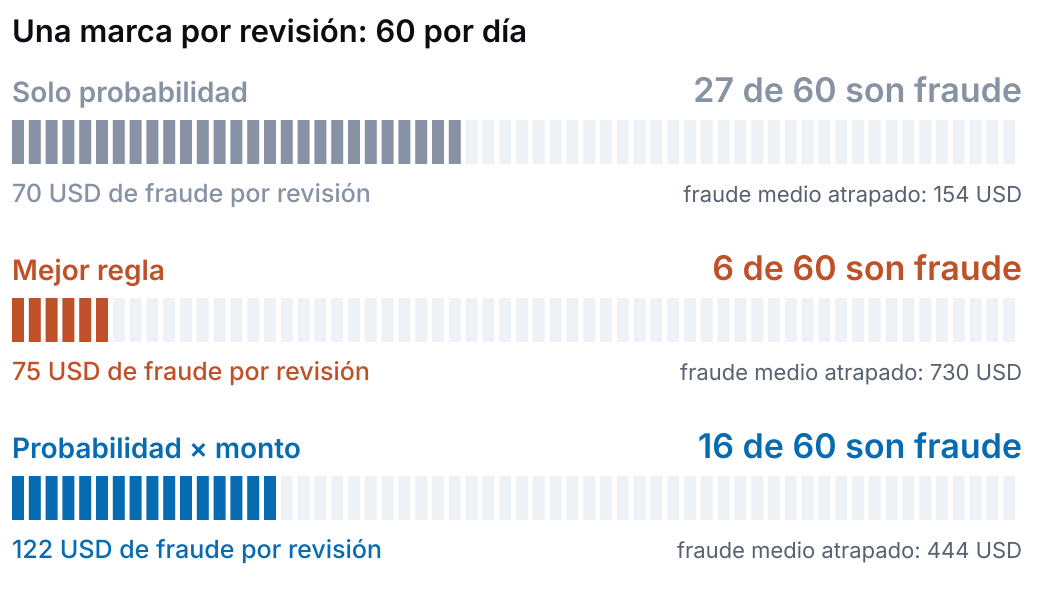

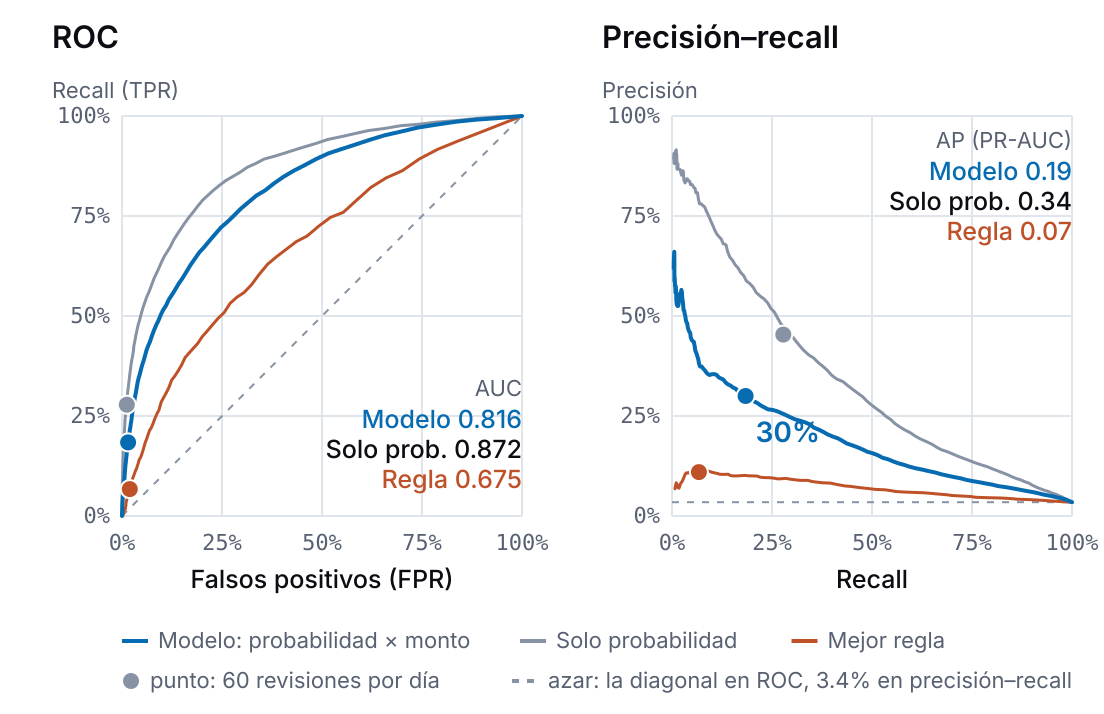

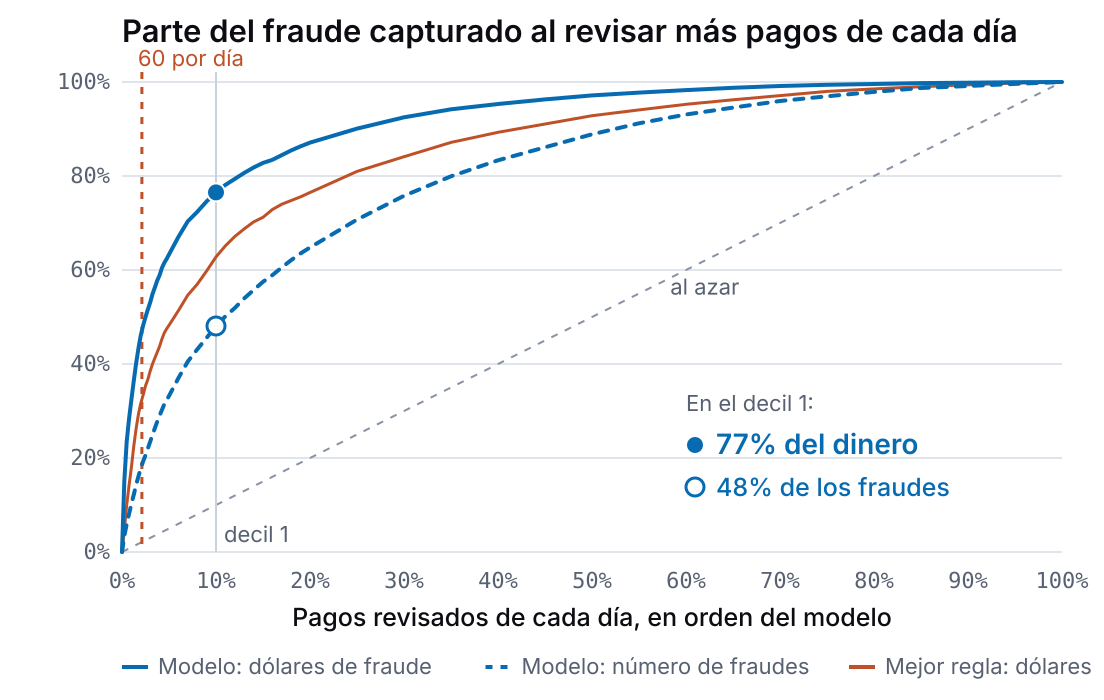

In [58]:
fig("exactitud", "roc", "ganancia")

**¿Las probabilidades son confiables? Calibración.** Por decil de probabilidad estimada, días 121–182.

In [59]:
p_t = T[FINAL]
dec_p = pd.qcut(p_t, 10, labels=range(1, 11))
cal = pd.DataFrame({"pagos": p_t.groupby(dec_p).size(), "probabilidad media estimada": p_t.groupby(dec_p).mean(),
                    "tasa de fraude observada": T["fraude"].groupby(dec_p).mean()}).rename_axis("decil de probabilidad")
display(cal.round(3))
br = {"Modelo": brier_score_loss(y_t, p_t), "Mejor logística": brier_score_loss(y_t, T[LOGIT]),
      "Asignar a todos la tasa media": brier_score_loss(y_t, np.full(len(y_t), y_t.mean()))}
display(pd.Series(br).round(4).rename("error de Brier").to_frame())
print(f"Fraudes con probabilidad estimada menor a 10%: {(p_t[y_t == 1] < .1).mean():.0%}; "
      f"con 50% o más: {(p_t[y_t == 1] >= .5).mean():.0%}")

,pagos,probabilidad media estimada,tasa de fraude observada
decil de probabilidad,,,
1,17600,0.002,0.002
2,17600,0.003,0.003
3,17600,0.004,0.004
4,17599,0.006,0.006
5,17600,0.008,0.009
6,17600,0.011,0.011
7,17599,0.016,0.017
8,17600,0.025,0.031
9,17600,0.045,0.056


,error de Brier
Modelo,0.027
Mejor logística,0.031
Asignar a todos la tasa media,0.033


Fraudes con probabilidad estimada menor a 10%: 50%; con 50% o más: 15%


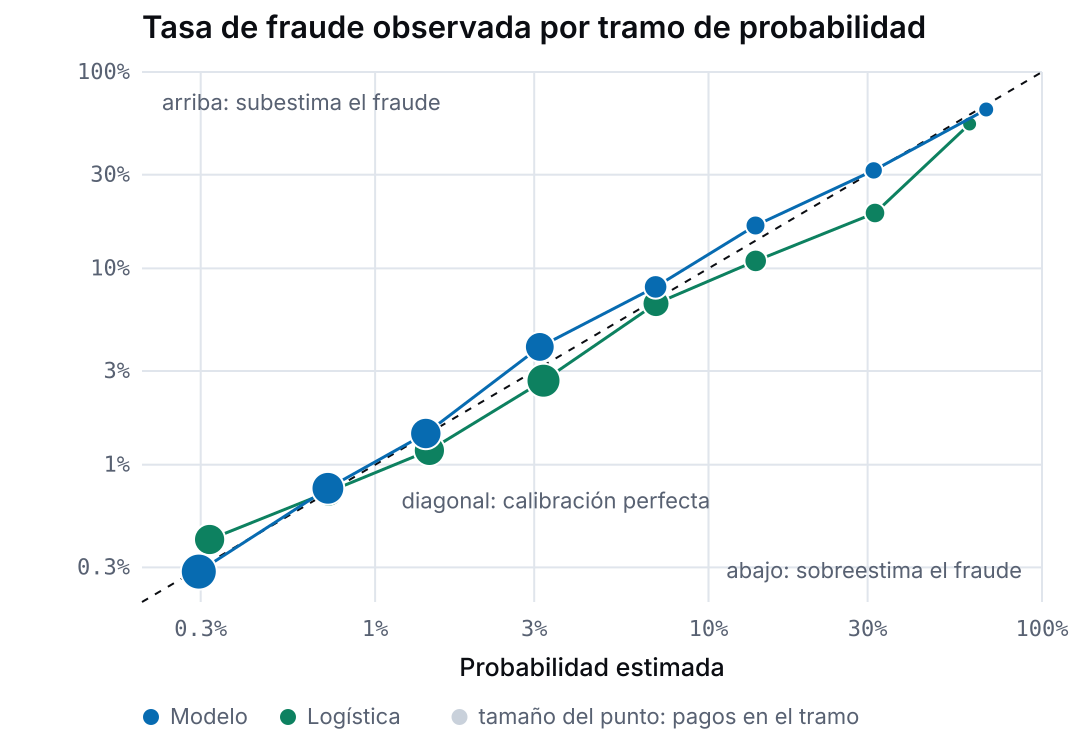

In [60]:
fig("calibracion")

Las probabilidades están calibradas: en cada decil, la probabilidad media estimada se parece a la tasa observada.
Que la mitad de los fraudes tenga probabilidad baja no es un error del modelo: esos fraudes se parecen a pagos
legítimos en todo lo que se observa. Con 60 revisiones por día no hacen falta probabilidades altas, sino un buen
**orden**: el decil más alto tiene una tasa de fraude varias veces el promedio.

**¿Por qué no se revisan primero los pagos con probabilidad más alta?** Se comparan, pago por pago, la cola por fraude
esperado y la cola del mismo modelo ordenada solo por probabilidad.

In [61]:
p_np, uft = T[FINAL].to_numpy(), y_t * m_t
sel_e, sel_p = seleccion(p_np * m_t, d_t, K), seleccion(p_np, d_t, K)
partes = {"en las dos colas": sel_e & sel_p, "solo en la cola por probabilidad": sel_p & ~sel_e, "solo en la cola por fraude esperado": sel_e & ~sel_p}
cambio = pd.DataFrame({n: {"pagos": int(k.sum()), "fraudes": int(y_t[k].sum()), "fraude detenido (mil USD)": mil(uft[k].sum()),
                           "fraude esperado (mil USD)": mil((p_np * m_t)[k].sum()), "monto mediano (USD)": round(float(np.median(m_t[k]))),
                           "probabilidad mediana": f"{np.median(p_np[k]):.0%}"} for n, k in partes.items()}).T
display(cambio)
n_dias = len(np.unique(d_t))
alta = {f"probabilidad ≥ {u:.0%}": {"pagos por día": round((p_np >= u).sum() / n_dias, 1),
                                     "entran a la cola": f"{((p_np >= u) & sel_e).sum() / (p_np >= u).sum():.0%}",
                                     "monto mediano de los que quedan fuera (USD)": round(float(np.median(m_t[(p_np >= u) & ~sel_e]))),
                                     "fraude que dejan pasar (mil USD)": mil(uft[(p_np >= u) & ~sel_e].sum())} for u in (.3, .5, .8)}
display(pd.DataFrame(alta).T)
a_, b_ = cambio.loc["solo en la cola por probabilidad"], cambio.loc["solo en la cola por fraude esperado"]
Markdown(f'''Las dos colas comparten {(sel_e & sel_p).sum() / sel_e.sum():.0%} de los pagos. En el resto, ordenar por probabilidad elige
{a_['fraudes']:,} fraudes que suman {a_['fraude detenido (mil USD)']:,.1f} mil USD (pagos de {a_['monto mediano (USD)']} USD en mediana);
ordenar por fraude esperado elige {b_['fraudes']:,} fraudes que suman {b_['fraude detenido (mil USD)']:,.1f} mil USD (pagos de
{b_['monto mediano (USD)']} USD en mediana). Menos fraudes, pero {b_['fraude detenido (mil USD)'] / a_['fraude detenido (mil USD)']:.0f} veces
más dinero.''')

,pagos,fraudes,fraude detenido (mil USD),fraude esperado (mil USD),monto mediano (USD),probabilidad mediana
en las dos colas,1613,773,194.7,201.2,158,49%
solo en la cola por probabilidad,2107,914,35.8,34.6,35,39%
solo en la cola por fraude esperado,2107,343,243.4,164.0,614,11%


,pagos por día,entran a la cola,monto mediano de los que quedan fuera (USD),fraude que dejan pasar (mil USD)
probabilidad ≥ 30%,51.4,44%,33,32.7
probabilidad ≥ 50%,22.4,55%,31,13.1
probabilidad ≥ 80%,4.8,75%,25,1.8


Las dos colas comparten 43% de los pagos. En el resto, ordenar por probabilidad elige
914 fraudes que suman 35.8 mil USD (pagos de 35 USD en mediana);
ordenar por fraude esperado elige 343 fraudes que suman 243.4 mil USD (pagos de
614 USD en mediana). Menos fraudes, pero 7 veces
más dinero.

**¿Y una cola mixta, que revise siempre los casos más claros?** Dos refinamientos posibles:

- **Reservar lugares:** los primeros N lugares de cada día para los pagos con mayor probabilidad, y el resto por fraude
  esperado.
- **Dar valor a cada fraude atrapado:** ordenar por probabilidad × (monto + V), donde V es lo que vale atrapar un fraude
  aparte de su monto (una comisión de contracargo, por ejemplo).

Además del fraude de la cola, se cuenta el **fraude posterior del mismo cliente** que se evita si un fraude revisado
lleva a bloquear la tarjeta: es el argumento a favor de revisar los fraudes chicos pero obvios, que a veces son pruebas
de una tarjeta robada. Cada variante se mide en desarrollo (días 61–120) y en la prueba. Es un análisis posterior: no
cambia el veredicto del protocolo.

In [62]:
todo["cliente"] = pd.factorize(todo["card1"] + "|" + todo["addr1"] + "|" + todo["alta"].astype(str))[0]


def cola_mixta(p, m, d, reserva=0, V=0.0):
    # Los primeros `reserva` lugares de cada día van a los pagos más probables; el resto, por probabilidad × (monto + V).
    arriba = seleccion(p, d, reserva) if reserva else np.zeros(len(p), bool)
    return seleccion(np.where(arriba, np.inf, p * (m + V)), d, K)


def detenido(sel, y, m, d, c):
    # Fraude de la cola, y fraude posterior del mismo cliente si el primer fraude revisado lleva a bloquear su tarjeta.
    rev = sel & (y == 1)
    dia_bloqueo = pd.Series(c).map(pd.Series(d[rev]).groupby(c[rev]).min()).to_numpy(dtype=float)
    despues = (y == 1) & ~sel & (d > dia_bloqueo)
    return (y * m)[sel].sum(), (y * m)[despues].sum(), int(y[sel].sum())


VARIANTES = {"actual: fraude esperado": (0, 0), "reserva 5 lugares": (5, 0), "reserva 10 lugares": (10, 0), "reserva 20 lugares": (20, 0),
             "probabilidad × (monto + 25)": (0, 25), "probabilidad × (monto + 100)": (0, 100), "solo probabilidad": (K, 0)}
ARCH = {"D1": "desarrollo_puntajes_D1", "D2": "desarrollo_puntajes_D2", "P1": "prueba_puntajes_P1", "P2": "prueba_puntajes_P2"}
acum = {}
for b, arch in ARCH.items():
    _, te = bloque(todo, *PART[b])
    g = pd.read_parquet(PROCESADOS / f"{arch}.parquet")
    assert np.array_equal(g["monto"].to_numpy(), te["TransactionAmt"].to_numpy())
    p, m, d, y, c = g[FINAL].to_numpy(), g["monto"].to_numpy(), g["dia"].to_numpy(), g["fraude"].to_numpy(), te["cliente"].to_numpy()
    for n, (r, V) in VARIANTES.items():
        x = acum.setdefault(("desarrollo" if b[0] == "D" else "prueba", n), np.zeros(3))
        x += detenido(cola_mixta(p, m, d, r, V), y, m, d, c)
mx = pd.DataFrame(acum, index=["en la cola", "evitado al bloquear", "fraudes"]).T
mx["total"] = mx["en la cola"] + mx["evitado al bloquear"]
base = mx.xs("actual: fraude esperado", level=1)
tabla = {}
for (etapa, n), v in mx.iterrows():
    tabla.setdefault(n, {})
    tabla[n][(etapa, "mil USD con bloqueo")] = mil(v["total"])
    tabla[n][(etapa, "contra la actual")] = pc(v["total"] / base.loc[etapa, "total"] - 1)
    tabla[n][(etapa, "fraudes atrapados")] = int(v["fraudes"])
mixta = pd.DataFrame(tabla).T
mejor_dev = mx.xs("desarrollo")["total"].idxmax()
r5 = mx.loc[("prueba", "reserva 5 lugares")] / mx.loc[("prueba", "actual: fraude esperado")] - 1
print(f"Mejor variante en desarrollo: {mejor_dev}. En la prueba, reservar 5 lugares cambia el dinero {pc(r5['total'])} "
      f"y los fraudes atrapados {pc(r5['fraudes'])}.")
mixta

Mejor variante en desarrollo: actual: fraude esperado. En la prueba, reservar 5 lugares cambia el dinero -0.9% y los fraudes atrapados +4.7%.


desarrollo                                                 prueba                                   
                             mil USD con bloqueo contra la actual fraudes atrapados mil USD con bloqueo contra la actual fraudes atrapados
actual: fraude esperado                    494.2            +0.0%              1048               461.5            +0.0%              1116
reserva 5 lugares                          490.0            -0.9%              1118               457.2            -0.9%              1169
reserva 10 lugares                         481.6            -2.6%              1175               456.7            -1.1%              1228
reserva 20 lugares                         472.9            -4.3%              1285               443.2            -4.0%              1348
probabilidad × (monto + 25)                479.4            -3.0%              1156               458.7            -0.6%              1247
probabilidad × (monto + 100)               431.3           -12.7%              1386               423.4            -8.3%              1473
solo probabilidad                          231.9           -53.1%              1518               253.9           -45.0%              1687

**No hace falta cambiar la cola.** Con o sin el efecto de bloquear la tarjeta, ordenar por fraude esperado es lo que
más dinero detiene, en desarrollo y en la prueba. El fraude evitado al bloquear es chico y parecido entre variantes:
los fraudes obvios que quedan fuera son de pocos dólares, y bloquear su tarjeta evita poco fraude posterior. Si el equipo valora
además el número de fraudes atrapados, reservar 5 de los 60 lugares para los casos más claros cuesta alrededor de 1%
del dinero y atrapa cerca de 5% más fraudes: es una decisión de operación, no del modelo.

### 5.2 Validación de negocio

La pregunta de la fase 1: **con las mismas 60 revisiones diarias, ¿el modelo detiene más dólares de fraude que la
práctica actual, por el margen fijado antes de la prueba?**

**Intervalos pareados, recalculados aquí.** Cada réplica remuestrea días con reemplazo, los mismos para todas las
políticas. Se vuelven a generar las 1,000 réplicas con la misma semilla y se comparan con las guardadas.

In [63]:
codigo(bootstrap)

`src/revisar/evaluacion.py` · `bootstrap`

```python
def bootstrap(scores: dict[str, np.ndarray], dia, y, monto, k, replicas=1000, semilla=0) -> pd.DataFrame:
    """Réplicas pareadas por día: se remuestrean días con reemplazo, los mismos para todas las políticas. Dentro de
    cada día, la cola de cada política queda como se eligió. Devuelve el total de cada réplica."""
    dias = np.unique(dia)
    total = {n: por_dia(s, dia, y, monto, k).reindex(dias, fill_value=0.0).to_numpy() for n, s in scores.items()}
    idx = np.random.default_rng(semilla).integers(0, len(dias), size=(replicas, len(dias)))
    return pd.DataFrame({n: v[idx].sum(axis=1) for n, v in total.items()})
```

In [64]:
filas, veredicto = [], {}
for x, (ini, fin) in P.items():
    g = PT[x]
    b = bootstrap(SC[x], g["dia"].to_numpy(), g["fraude"].to_numpy(), g["monto"].to_numpy(), K, 1000, semilla=ini)
    guardadas = pd.read_csv(RAIZ / "resultados" / f"bootstrap_{x}.csv")
    assert all(np.allclose(b[c], guardadas[c]) for c in b.columns), "las réplicas no coinciden con las guardadas"
    cx = {}
    for c in (REGLA, LOGIT, PUB):
        rel = b[FINAL] / b[c] - 1
        lo, hi = rel.quantile(0.025), rel.quantile(0.975)
        assert abs(lo - R[x]["contrastes"][c]["rel_ic95"][0]) < 1e-9 and abs(hi - R[x]["contrastes"][c]["rel_ic95"][1]) < 1e-9
        cx[c] = (vivo[x][FINAL] / vivo[x][c] - 1, lo)
        filas.append({"periodo": x, "contra": NOMBRE[c], "ventaja": pc(cx[c][0]), "IC 95%": ic((lo, hi))})
    veredicto[x] = {"H1_regla": cx[REGLA][0] >= U["H1"] and cx[REGLA][1] > 0,
                    "H2_logistica": cx[LOGIT][0] >= U["H2"] and cx[LOGIT][1] > 0, "H3_publicado": cx[PUB][1] > 0}
assert veredicto == R["veredicto"]
display(pd.DataFrame(filas).set_index(["periodo", "contra"]))
display(pd.DataFrame(veredicto).rename(index={"H1_regla": "H1 · mejor regla", "H2_logistica": "H2 · mejor logística", "H3_publicado": "H3 · solo probabilidad"}))
print("Éxito del caso (H1, H2 y H3 en los dos meses):", all(all(v.values()) for v in veredicto.values()))

ventaja            IC 95%
periodo contra                                                                  
P1      Mejor regla: tasa por segmento × monto          +30.1%   +16.8% a +49.8%
        Mejor logística (C = 0.003, F3)                 +13.1%    +7.0% a +21.8%
        Solo probabilidad (enfoque de la competencia)  +110.1%  +76.9% a +147.4%
P2      Mejor regla: tasa por segmento × monto          +63.4%   +39.7% a +97.0%
        Mejor logística (C = 0.003, F3)                 +22.2%    +8.7% a +39.3%
        Solo probabilidad (enfoque de la competencia)   +74.5%   +54.7% a +98.3%

,P1,P2
H1 · mejor regla,True,True
H2 · mejor logística,True,True
H3 · solo probabilidad,True,True


Éxito del caso (H1, H2 y H3 en los dos meses): True


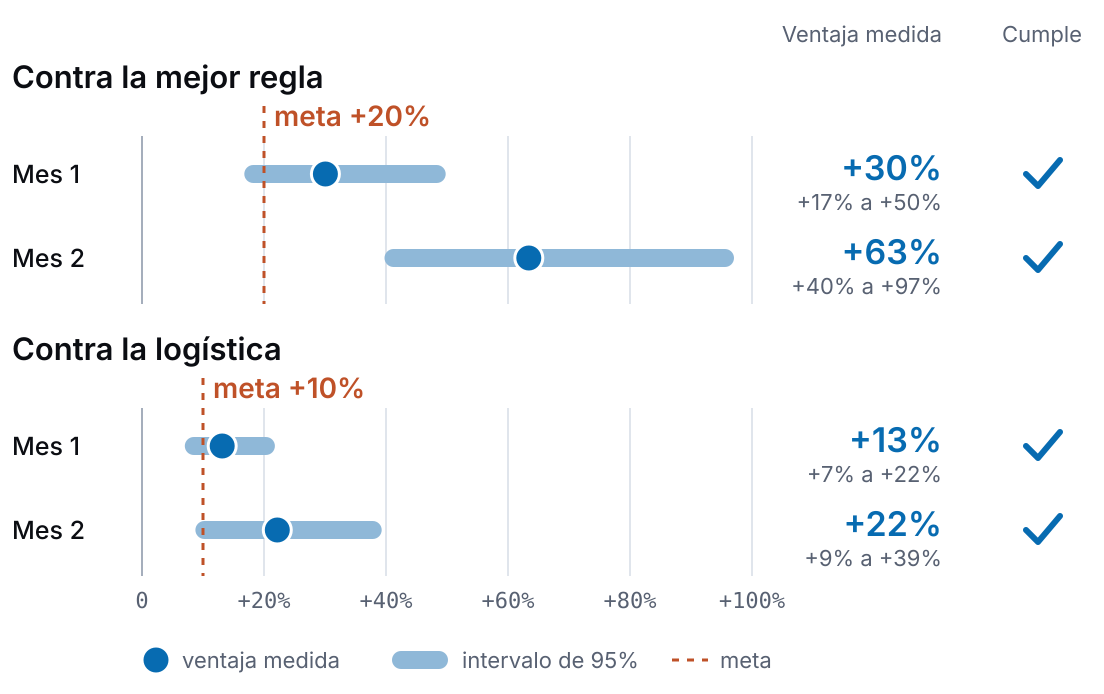

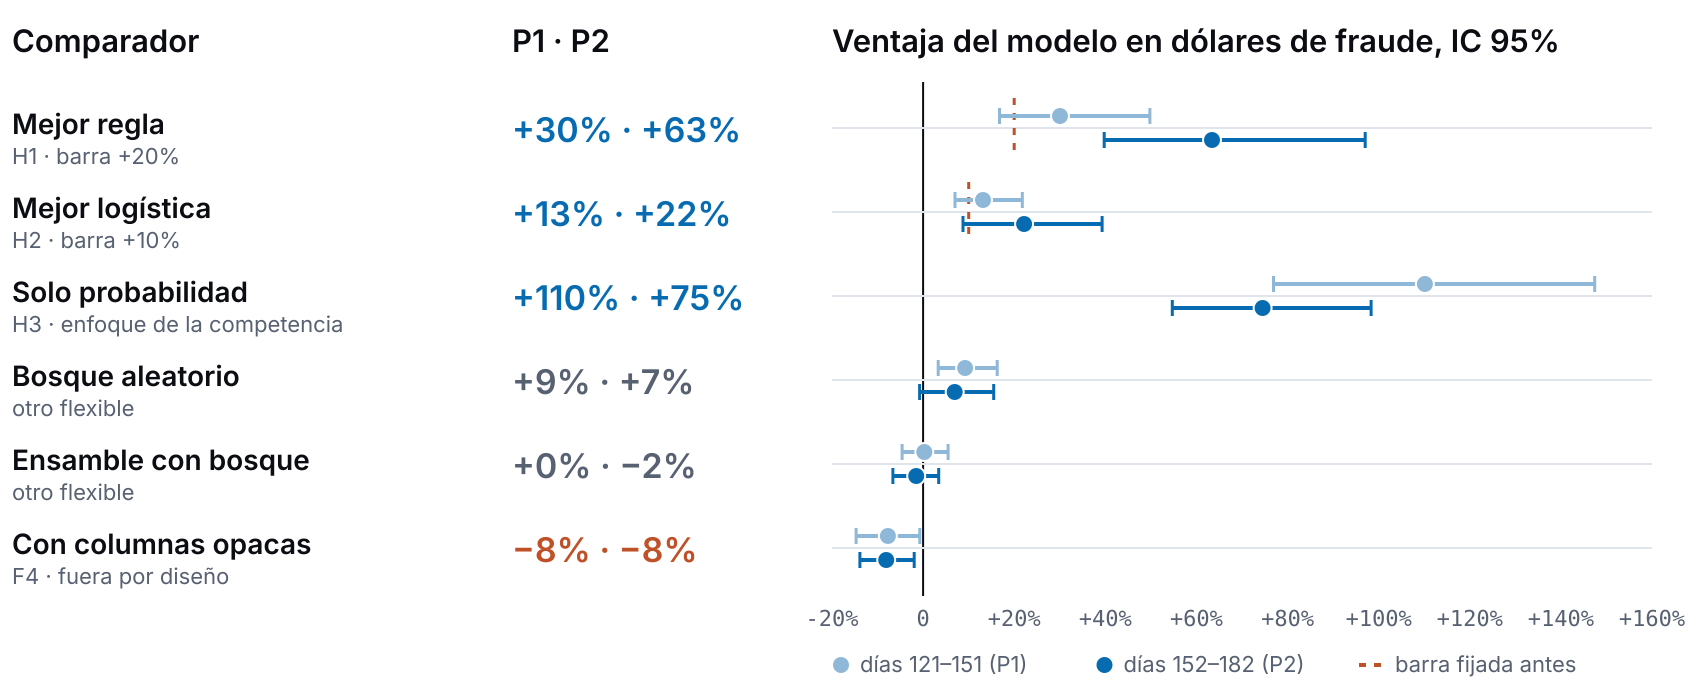

In [65]:
fig("hipotesis", "intervalos")

**Robustez.** Ventaja del modelo con otros cupos, sin los pagos más caros, con el monto topado y en los días 121–144,
que ningún estudio anterior había leído.

In [66]:
rb = {}
for x in P:
    r = R[x]["robustez"]
    for c, nom in ((REGLA, "regla"), (LOGIT, "logística")):
        rb[f"{nom} · {x}"] = {"principal (60 por día)": pc(R[x]["contrastes"][c]["rel"]), "30 por día": pc(r["K"][c]["30"]),
                              "120 por día": pc(r["K"][c]["120"]), "sin pagos sobre el p99": pc(r["sin_top1"][c]),
                              "monto topado en el p99": pc(r["topado"][c]), "días que gana": f"{R[x]['dias_que_gana'][c]} de {R[x]['n_dias']}",
                              "días 121–144": pc(R[x]["limpio"]["contrastes"][c]["rel"]) if x == "P1" else "—"}
pd.DataFrame(rb)

,regla · P1,logística · P1,regla · P2,logística · P2
principal (60 por día),+30.1%,+13.1%,+63.4%,+22.2%
30 por día,+80.6%,+13.6%,+89.8%,+28.6%
120 por día,+25.7%,+12.0%,+44.1%,+15.5%
sin pagos sobre el p99,+20.6%,+8.8%,+58.0%,+22.1%
monto topado en el p99,+37.1%,+15.6%,+77.9%,+28.7%
días que gana,26 de 31,24 de 31,28 de 31,24 de 31
días 121–144,+22.6%,+11.0%,—,—


**¿Sobreajuste a los periodos? Validación cruzada en el tiempo.** Los cuatro bloques son los pliegues de una
validación con origen móvil: cada uno entrena solo con días anteriores, con 30 de margen, y se evalúa en un mes que su
modelo no vio. D1 y D2 se usaron para elegir; P1 y P2 no. Si la elección estuviera sobreajustada a D1 y D2, el modelo
caería en P1 y P2. Las políticas elegibles son las reglas, las logísticas y los modelos flexibles con F2 o F3.

In [67]:
filas = {}
for b, arch in ARCH.items():
    g = pd.read_parquet(PROCESADOS / f"{arch}.parquet")
    d_, y_, m_ = g["dia"].to_numpy(), g["fraude"].to_numpy(), g["monto"].to_numpy()
    eleg = [c for c in g.columns if c not in ("dia", "fraude", "monto") and not c.startswith("ISO") and not c.endswith(("F1", "F4"))]
    usd = {c: dinero(puntaje(c.split("|")[0], g[c].to_numpy(), m_), d_, y_, m_, K) for c in eleg}
    solo_p, orac = dinero(g[FINAL].to_numpy(), d_, y_, m_, K), dinero(y_ * m_, d_, y_, m_, K)
    dm, dr = (por_dia(puntaje(n.split("|")[0], g[n].to_numpy(), m_), d_, y_, m_, K) for n in (FINAL, REGLA))
    orden = sorted(eleg, key=lambda c: -usd[c])
    filas[b] = {"uso": "elegir" if b[0] == "D" else "prueba", "días": f"{PART[b][0]}–{PART[b][1]}",
                "contra la regla": pc(usd[FINAL] / usd[REGLA] - 1), "contra la logística": pc(usd[FINAL] / usd[LOGIT] - 1),
                "contra solo probabilidad": pc(usd[FINAL] / solo_p - 1), "parte del oráculo": f"{usd[FINAL] / orac:.0%}",
                "lugar del modelo": f"{orden.index(FINAL) + 1} de {len(eleg)}",
                "quién le gana": ", ".join(f"{c} ({pc(usd[c] / usd[FINAL] - 1)})" for c in orden[:orden.index(FINAL)]) or "nadie",
                "días que gana a la regla": f"{int((dm > dr).sum())} de {len(dm)}"}
pliegues = pd.DataFrame(filas).T
assert all(v.startswith("+") for c in ("contra la regla", "contra la logística", "contra solo probabilidad") for v in pliegues[c])
pliegues

,uso,días,contra la regla,contra la logística,contra solo probabilidad,parte del oráculo,lugar del modelo,quién le gana,días que gana a la regla
D1,elegir,61–90,+150.6%,+28.7%,+82.3%,41%,1 de 28,nadie,27 de 30
D2,elegir,91–120,+31.1%,+3.9%,+162.8%,46%,3 de 28,"ENS|F3 (+3.3%), ENS|F2 (+2.9%)",23 de 30
P1,prueba,121–151,+30.1%,+13.1%,+110.1%,49%,1 de 28,nadie,26 de 31
P2,prueba,152–182,+63.4%,+22.2%,+74.5%,52%,2 de 28,ENS|F3 (+1.5%),28 de 31


El modelo gana a la regla, a la logística y al orden por probabilidad en los cuatro pliegues, y su parte del oráculo
no cae al pasar de los pliegues que lo eligieron a los de prueba: no hay señal de que la elección se sobreajustara a D1 y
D2. Solo el ensamble XGBoost + bosque le gana en algún pliegue, por pocos puntos; perdió mucho en D1, y la regla de
selección, escrita antes del torneo, pedía ganar en el total. Además, los hiperparámetros no se ajustaron con estos
periodos (4.3), y la única búsqueda que sí ajustó, la de variables, mostró sobreajuste en la confirmación y se
descartó (3.3).

**Costo por revisión.** Si revisar cuesta, cada política elige su cupo en desarrollo para cada costo; el neto
(recuperado − costo) se mide en la prueba.

In [68]:
ct = pd.DataFrame([{"costo por revisión": e["costo"], "recupera": f"{e['recupera']:.0%}",
                    **{f"{k}: cupo": e[k]["K"] for k in ("modelo", "logistica", "regla")},
                    **{f"{k}: neto (mil USD)": mil(e[k]["neto_prueba"]) for k in ("modelo", "logistica", "regla")}} for e in L["costos"]])
gana = sum(e["modelo"]["neto_prueba"] > max(e["logistica"]["neto_prueba"], e["regla"]["neto_prueba"]) for e in L["costos"])
print(f"El modelo deja más neto que la regla y que la logística en {gana} de {len(L['costos'])} escenarios")
ct

El modelo deja más neto que la regla y que la logística en 14 de 14 escenarios


,costo por revisión,recupera,modelo: cupo,logistica: cupo,regla: cupo,modelo: neto (mil USD),logistica: neto (mil USD),regla: neto (mil USD)
0,1,100%,1498,1500,1494,832.1,815.5,795.9
1,2,100%,1117,1353,1491,766.0,729.4,702.6
2,5,100%,621,709,764,648.0,588.8,544.1
3,10,100%,450,424,489,513.4,465.0,399.3
4,20,100%,178,188,205,423.1,358.2,268.9
5,50,100%,66,70,48,249.4,180.1,114.2
6,100,100%,30,17,0,128.0,54.0,0.0
7,1,50%,1117,1353,1491,383.0,364.7,351.3
8,2,50%,815,878,996,334.8,312.3,289.4
9,5,50%,450,424,489,256.7,232.5,199.6


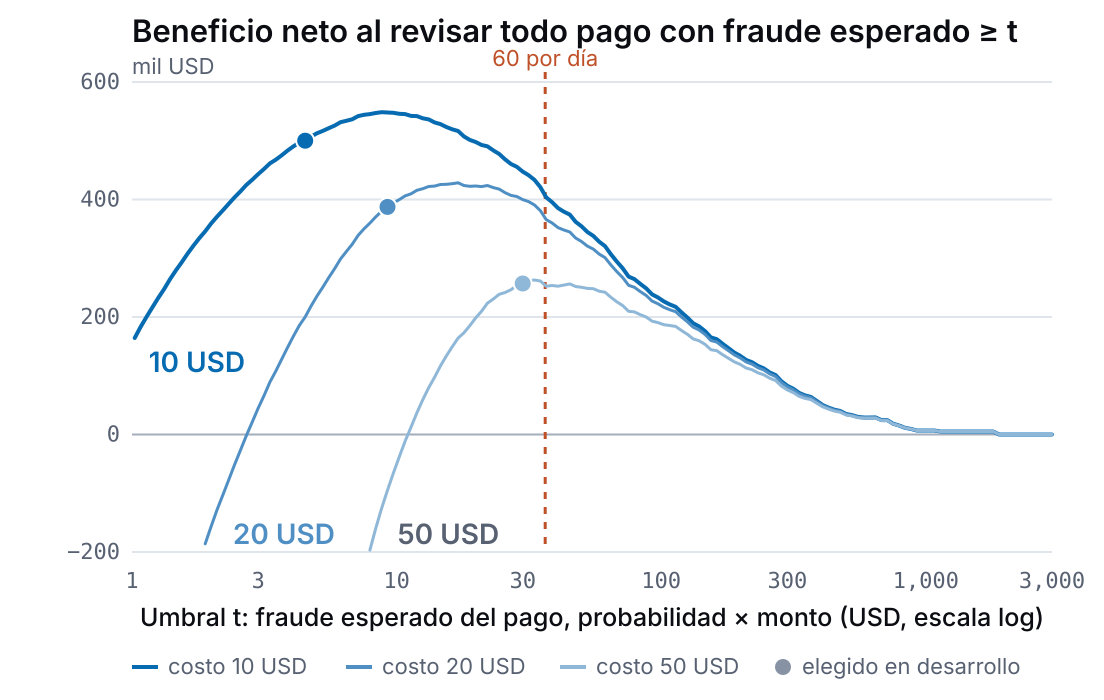

In [69]:
fig("montana")

**Traza del dinero.** Cada dólar de fraude del mes cae en una sola categoría y las cuatro suman el fraude total.

In [70]:
tr_ = pd.DataFrame(PJ["traza"]).T
for x in P:
    assert abs(tr_.loc[x, ["ambos", "solo_modelo", "solo_regla", "ninguno"]].sum() - tr_.loc[x, "fraude_total"]) < 0.01
(tr_[["fraude_total", "ambos", "solo_modelo", "solo_regla", "ninguno"]] / 1e3).round(1).rename(columns=lambda c: f"{c} (mil USD)")

,fraude_total (mil USD),ambos (mil USD),solo_modelo (mil USD),solo_regla (mil USD),ninguno (mil USD)
P1,472.7,134.6,76.9,28.0,233.2
P2,477.4,111.6,115.1,27.2,223.5


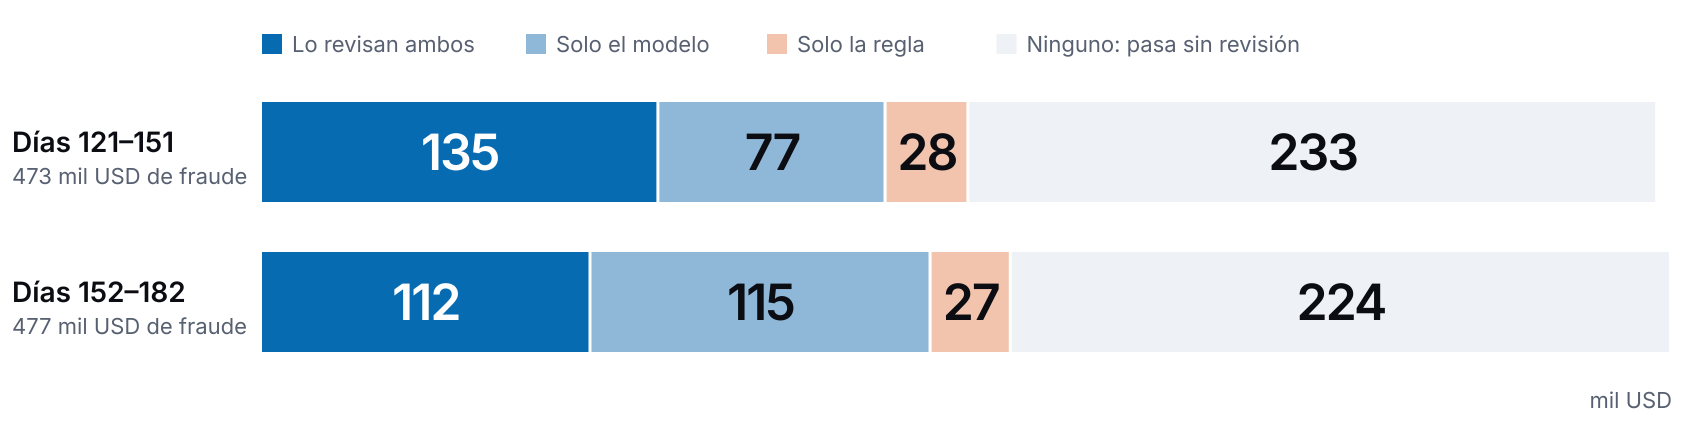

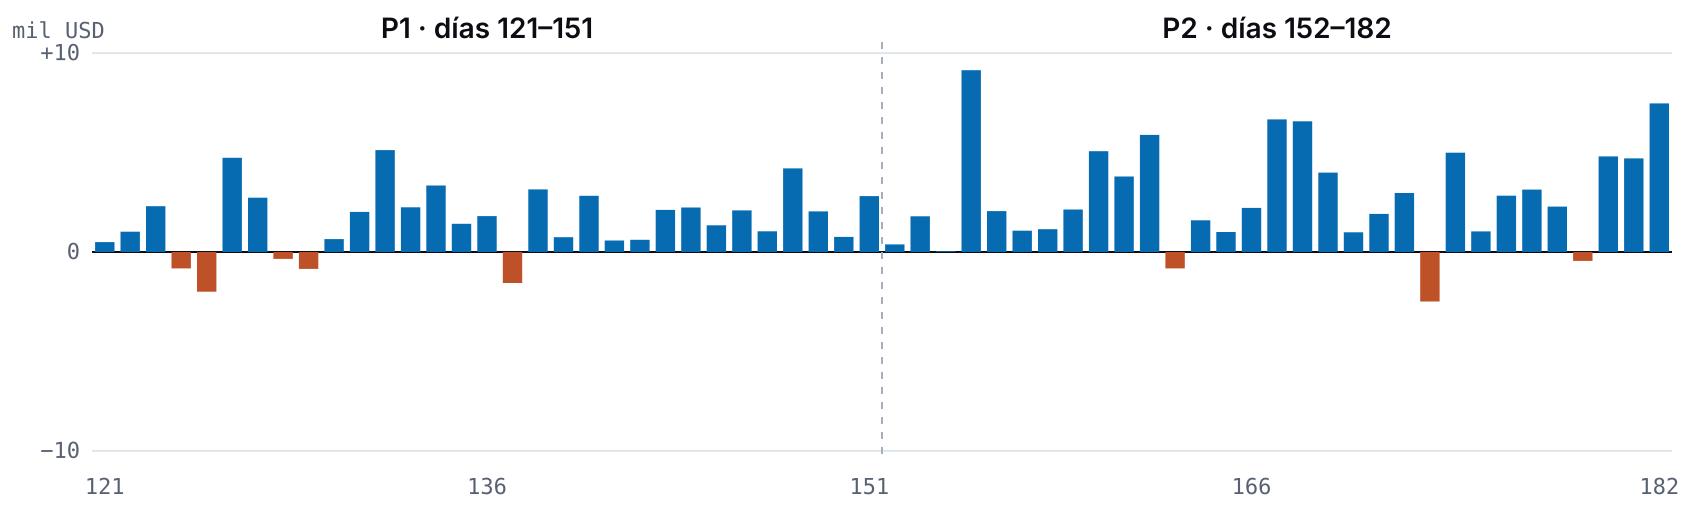

In [71]:
fig("traza", "diario")

In [72]:
tot = lambda n: sum(vivo[x][n] for x in P)
Markdown(f'''**Respuesta a la pregunta de negocio: sí.** Con las mismas 60 revisiones diarias, en los días 121–182 el modelo lleva
{tot(FINAL) / 1e3:,.0f} mil USD de fraude a la cola, contra {tot(REGLA) / 1e3:,.0f} mil de la mejor regla y {tot(LOGIT) / 1e3:,.0f} mil de la
logística: {(tot(FINAL) - tot(REGLA)) / 1e3:,.0f} mil USD más que la práctica actual. Las tres metas fijadas antes de la prueba se
cumplen en los dos meses, la ventaja resiste sin los pagos más caros y con otros cupos, y el modelo gana en la mayoría de
los días.''')

**Respuesta a la pregunta de negocio: sí.** Con las mismas 60 revisiones diarias, en los días 121–182 el modelo lleva
438 mil USD de fraude a la cola, contra 301 mil de la mejor regla y 372 mil de la
logística: 137 mil USD más que la práctica actual. Las tres metas fijadas antes de la prueba se
cumplen en los dos meses, la ventaja resiste sin los pagos más caros y con otros cupos, y el modelo gana en la mayoría de
los días.

### 5.3 Lectura posterior: ¿las variables nuevas habrían ayudado en la prueba?

Una sola lectura de los días 121–182 con las variables de la búsqueda de 3.3, recalculada aquí. F3 reconstruido debe
reproducir la corrida congelada.

In [73]:
lec = {}
for x in P:
    a = pd.read_parquet(PROCESADOS / f"anexo_puntajes_{x}.parquet")
    d_, y_, m_ = a["dia"].to_numpy(), a["fraude"].to_numpy(), a["monto"].to_numpy()
    lec[x] = {n: dinero(a[n].to_numpy() * m_, d_, y_, m_, K) for n in ("F3", "elegido", "logit_F3", "logit_elegido")}
    assert abs(lec[x]["F3"] - R[x]["usd"][FINAL]) < 0.01, "F3 no reproduce la prueba congelada"
pd.DataFrame({x: {"F3 (mil USD)": mil(lec[x]["F3"]), "variables nuevas (mil USD)": mil(lec[x]["elegido"]),
                  "variables nuevas contra F3": f"{pc(AX[x]['contrastes']['elegido_vs_F3']['rel'])} ({ic(AX[x]['contrastes']['elegido_vs_F3']['rel_ic95'])})",
                  "logística: nuevas contra F3": f"{pc(AX[x]['contrastes']['logit_elegido_vs_logit_F3']['rel'])} ({ic(AX[x]['contrastes']['logit_elegido_vs_logit_F3']['rel_ic95'])})"}
              for x in P})

,P1,P2
F3 (mil USD),211.4,226.7
variables nuevas (mil USD),214.6,226.7
variables nuevas contra F3,+1.5% (-2.4% a +6.2%),+0.0% (-3.1% a +3.8%)
logística: nuevas contra F3,+5.1% (+0.5% a +10.0%),+2.2% (-1.7% a +7.2%)


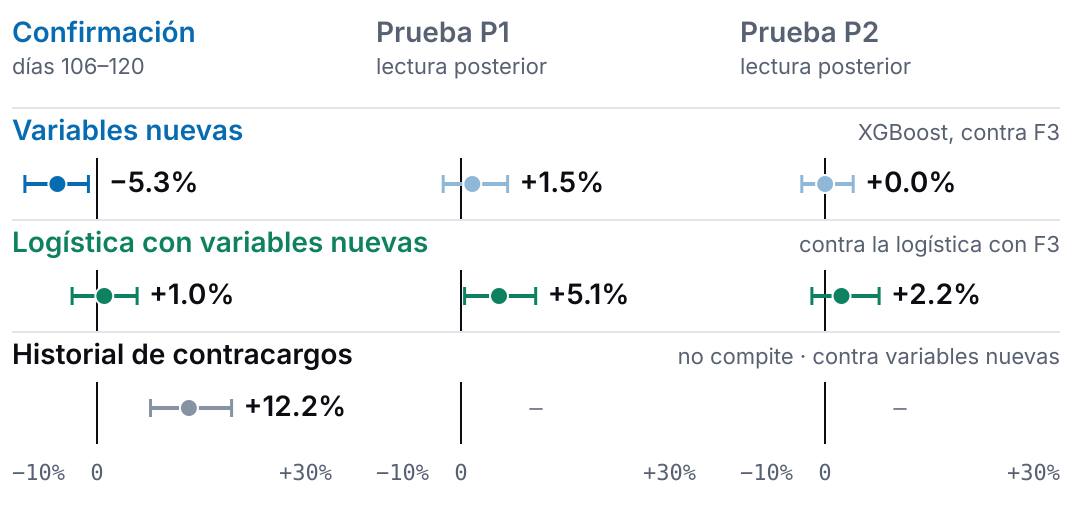

In [74]:
fig("confirmacion")

## 6. Despliegue

### 6.1 Propuesta de implementación

| Etapa | Cuándo | Qué se hace |
|---|---|---|
| Operación | Cada noche | Se puntúan los pagos del día y los 60 con mayor fraude esperado pasan a la cola. La decisión sobre cada pago sigue siendo del equipo. |
| Etiquetas | A los 30 días | Llega el contracargo y cada pago queda etiquetado. |
| Reentrenamiento | Cada semana | Con los pagos de más de 30 días, que ya tienen etiqueta, con el mismo código (`Diseno` + XGBoost). |
| Piloto | Primer mes | Los días se asignan al azar a la cola actual o a la del modelo, para medir el efectivo recuperado. |
| Respaldo | Si el modelo falla | Si dos semanas seguidas detiene menos que la regla, se vuelve a la tabla por segmento. |

El proceso nocturno es corto: `cargar` arma el historial con los pagos hasta el cierre, el modelo de la semana puntúa,
`puntaje` multiplica por el monto y `seleccion` toma los 60 primeros. **La lista de una noche**, día 166, con los puntajes
del modelo congelado:

In [75]:
x, noche = "P2", PJ["dia"]["dia"]
_, te2 = bloque(todo, *P[x])
g = PT[x].assign(producto=te2["ProductCD"].to_numpy(), tarjeta=te2["card4"].to_numpy() + " " + te2["card6"].to_numpy())
h = g[g["dia"] == noche].copy()
h["fraude esperado"] = h[FINAL] * h["monto"]
h["en la cola"] = seleccion(h["fraude esperado"].to_numpy(), h["dia"].to_numpy(), K)
cola = h[h["en la cola"]].sort_values("fraude esperado", ascending=False)
assert abs((cola["fraude"] * cola["monto"]).sum() - PJ["dia"]["modelo_usd"]) < 0.01
print(f"Día {noche}: {len(h):,} pagos; la cola tiene {len(cola)}. A los 30 días: {int(cola['fraude'].sum())} fraudes y "
      f"{(cola['fraude'] * cola['monto']).sum():,.0f} USD detenidos, de {(h['fraude'] * h['monto']).sum():,.0f} USD de fraude del día.")
top = cola.head(12)
top.assign(probabilidad=top[FINAL].map("{:.1%}".format), resultado=np.where(top["fraude"] == 1, "fraude", "legítimo"))[
    ["producto", "tarjeta", "monto", "probabilidad", "fraude esperado", "resultado"]].round(1).reset_index(drop=True).rename(index=lambda i: i + 1)

Día 166: 2,931 pagos; la cola tiene 60. A los 30 días: 10 fraudes y 4,047 USD detenidos, de 10,319 USD de fraude del día.


,producto,tarjeta,monto,probabilidad,fraude esperado,resultado
1,W,visa credit,944.0,49.2%,464.2,fraude
2,W,visa credit,1761.0,21.3%,374.3,legítimo
3,W,visa credit,664.0,50.2%,333.2,legítimo
4,W,discover credit,542.0,46.5%,251.8,legítimo
5,W,discover credit,872.0,27.7%,241.7,legítimo
6,W,mastercard credit,884.0,21.6%,191.1,fraude
7,W,mastercard debit,2161.0,8.7%,187.0,legítimo
8,W,mastercard debit,527.0,29.1%,153.2,legítimo
9,W,visa credit,554.0,25.5%,141.4,fraude
10,R,visa credit,300.0,46.7%,140.0,legítimo


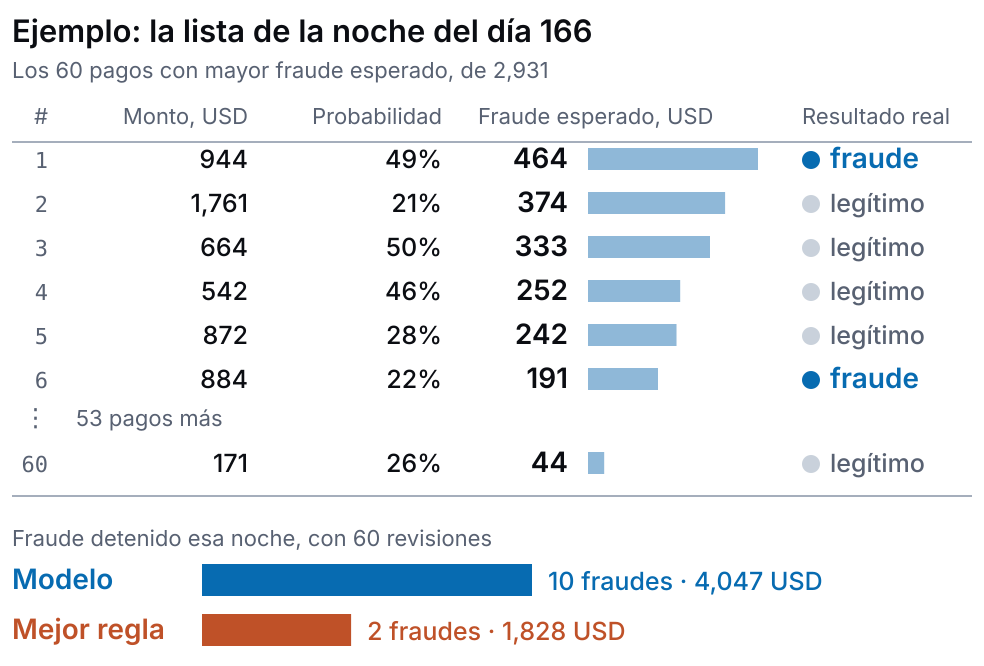

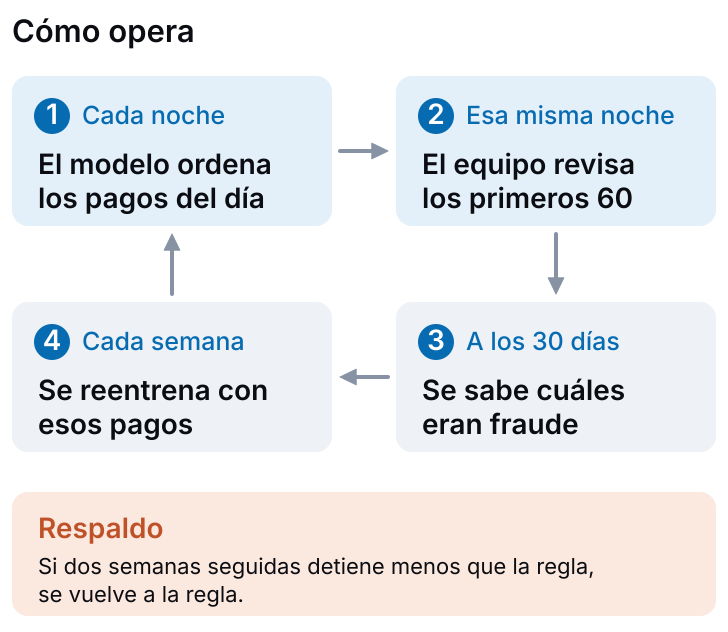

In [76]:
fig("cola_noche", "operacion")

### 6.2 Mantenimiento: monitoreo de la degradación

| Qué se mide | Cada cuándo | Señal de alarma | Qué se hace |
|---|---|---|---|
| Dólares detenidos: modelo contra la regla, en días del piloto | Semana | Dos semanas seguidas por debajo de la regla | Volver a la regla y revisar |
| Dólares por revisión y precisión de la cola | Semana | Caída sostenida frente a las semanas anteriores | Revisar datos y reentrenar |
| Deriva de los datos (PSI del monto y de la probabilidad) | Semana | PSI > 0.25 | Revisar qué cambió antes de confiar en la cola |
| Mezcla de la cola (producto, monto medio) | Semana | Cambio brusco | Revisar con el equipo |

Para ver cómo se comporta ese tablero, se corre aquí sobre los dos meses de prueba, por semana (la última semana de
cada mes junta 10 días). La edad del modelo cuenta los días desde su último día de entrenamiento.

In [77]:
def psi(referencia, actual, cubetas=10):
    # Índice de estabilidad poblacional: cuánto cambió la distribución de actual frente a referencia.
    cortes = np.quantile(referencia, np.linspace(0, 1, cubetas + 1)[1:-1])
    a = np.bincount(np.searchsorted(cortes, referencia), minlength=cubetas) / len(referencia)
    b = np.bincount(np.searchsorted(cortes, actual), minlength=cubetas) / len(actual)
    a, b = np.clip(a, 1e-6, None), np.clip(b, 1e-6, None)
    return float(((b - a) * np.log(b / a)).sum())


filas = []
for x, (ini, fin) in P.items():
    tr, te = bloque(todo, ini, fin)
    g = PT[x]
    d_, y_, m_ = g["dia"].to_numpy(), g["fraude"].to_numpy(), g["monto"].to_numpy()
    sel_m, sel_r = seleccion(SC[x][FINAL], d_, K), seleccion(SC[x][REGLA], d_, K)
    semana = np.minimum((d_ - ini) // 7, 3)
    ultimo = tr["dia"].max()
    p_ref = g[FINAL].to_numpy()[semana == 0]
    for w in range(4):
        k = semana == w
        km, kr = k & sel_m, k & sel_r
        filas.append({"mes": x, "semana": w + 1, "días": f"{d_[k].min()}–{d_[k].max()}", "edad del modelo (días)": f"{d_[k].min() - ultimo}–{d_[k].max() - ultimo}",
                      "modelo (mil USD)": mil((y_ * m_)[km].sum()), "regla (mil USD)": mil((y_ * m_)[kr].sum()),
                      "parte del fraude que detiene": (y_ * m_)[km].sum() / (y_ * m_)[k].sum(),
                      "USD por revisión": (y_ * m_)[km].sum() / km.sum(), "precisión de la cola": y_[km].mean(),
                      "monto medio en la cola": m_[km].mean(), "producto C en la cola": (te["ProductCD"].to_numpy()[km] == "C").mean(),
                      "PSI del monto": psi(np.log1p(tr["TransactionAmt"].to_numpy()), np.log1p(m_[k])),
                      "PSI de la probabilidad": psi(p_ref, g[FINAL].to_numpy()[k])})
mon = pd.DataFrame(filas)
mon["modelo debajo de la regla"] = mon["modelo (mil USD)"] < mon["regla (mil USD)"]
alarma = any(mon.groupby("mes")["modelo debajo de la regla"].apply(lambda s: (s & s.shift(fill_value=False)).any()))
print("¿Se habría activado el respaldo (dos semanas seguidas debajo de la regla)?", "sí" if alarma else "no")
formato = {"parte del fraude que detiene": "{:.0%}", "USD por revisión": "{:,.0f}", "precisión de la cola": "{:.0%}",
           "monto medio en la cola": "{:,.0f}", "producto C en la cola": "{:.0%}", "PSI del monto": "{:.3f}", "PSI de la probabilidad": "{:.3f}"}
mon.assign(**{c: mon[c].map(f.format) for c, f in formato.items()}).drop(columns="modelo debajo de la regla").set_index(["mes", "semana"])

¿Se habría activado el respaldo (dos semanas seguidas debajo de la regla)? no


días edad del modelo (días)  modelo (mil USD)  regla (mil USD) parte del fraude que detiene USD por revisión precisión de la cola  \
mes semana                                                                                                                                         
P1  1       121–127                  31–37              63.0             54.5                          47%              150                  39%   
    2       128–134                  38–44              49.6             37.4                          43%              118                  35%   
    3       135–141                  45–51              57.6             48.7                          50%              137                  33%   
    4       142–151                  52–61              41.3             22.0                          38%               69                  26%   
P2  1       152–158                  31–37              40.9             25.2                          40%               97                  24%   
    2       159–165                  38–44              39.3             20.6                          45%               94                  25%   
    3       166–172                  45–51              51.7             26.4                          50%              123                  30%   
    4       173–182                  52–61              94.8             66.5                          51%              158                  30%   

           monto medio en la cola producto C en la cola PSI del monto PSI de la probabilidad  
mes semana                                                                                    
P1  1                         489                   34%         0.019                  0.000  
    2                         481                   23%         0.014                  0.007  
    3                         573                   25%         0.018                  0.012  
    4                         512                   22%         0.016                  0.007  
P2  1                         732                   13%         0.013                  0.000  
    2                         692                    8%         0.008                  0.035  
    3                         729                   14%         0.016                  0.049  
    4                         660                   13%         0.011                  0.023

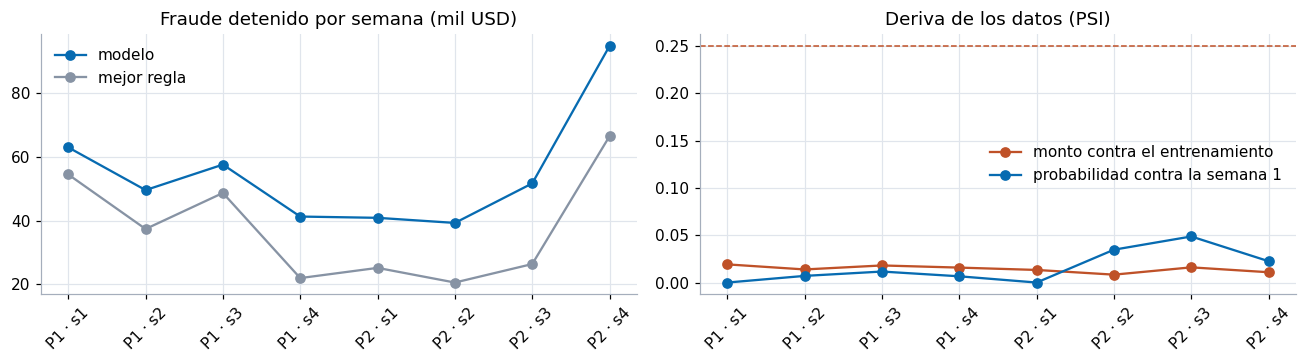

Parte del fraude que detiene el modelo según la semana del mes (promedio de P1 y P2): semana 1: 43%, semana 2: 44%, semana 3: 50%, semana 4: 45%


In [78]:
f, ax = plt.subplots(1, 2, figsize=(12, 3.4))
etq = mon["mes"] + " · s" + mon["semana"].astype(str)
ax[0].plot(etq, mon["modelo (mil USD)"], "o-", color=AZUL, label="modelo")
ax[0].plot(etq, mon["regla (mil USD)"], "o-", color=GRIS, label="mejor regla")
ax[0].set_title("Fraude detenido por semana (mil USD)"); ax[0].legend(frameon=False)
ax[1].plot(etq, mon["PSI del monto"], "o-", color=NARANJA, label="monto contra el entrenamiento")
ax[1].plot(etq, mon["PSI de la probabilidad"], "o-", color=AZUL, label="probabilidad contra la semana 1")
ax[1].axhline(0.25, color=NARANJA, ls="--", lw=1); ax[1].set_title("Deriva de los datos (PSI)"); ax[1].legend(frameon=False)
for a in ax:
    a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
edad = mon.groupby("semana")["parte del fraude que detiene"].mean()
print("Parte del fraude que detiene el modelo según la semana del mes (promedio de P1 y P2):",
      ", ".join(f"semana {w}: {v:.0%}" for w, v in edad.items()))

En los dos meses el modelo supera a la regla todas las semanas, la deriva del monto y de la probabilidad queda lejos
del umbral y la parte del fraude que detiene no cae de forma clara entre la semana 1 y la 4, con modelos de 31 a 61
días de edad. El reentrenamiento semanal es una precaución: el monitoreo es lo que dice cuándo hace falta.

## 7. Conclusiones

In [79]:
Markdown(f'''Con las mismas 60 revisiones diarias, en los días 121–182 la mejor regla lleva {tot(REGLA) / 1e3:,.0f} mil USD de fraude a la cola,
la logística {tot(LOGIT) / 1e3:,.0f} mil y el modelo {tot(FINAL) / 1e3:,.0f} mil. Contra la regla, la ventaja es de
{pc(R['P1']['contrastes'][REGLA]['rel'])} y {pc(R['P2']['contrastes'][REGLA]['rel'])}; contra la logística, de
{pc(R['P1']['contrastes'][LOGIT]['rel'])} y {pc(R['P2']['contrastes'][LOGIT]['rel'])}. Las tres hipótesis fijadas antes de la prueba
se cumplen en los dos meses.

**Por qué confiar en el resultado**

- La partición es en el tiempo, con 30 días de margen, y ninguna variable usa el futuro ni la etiqueta (3.2, 4.2).
- El modelo, los comparadores y las metas se congelaron antes de la prueba, que se corrió una sola vez (1.3, 4.1).
- Cada modelo entrena con todos los pagos ya etiquetados; el modelo final, entrenado de nuevo aquí, vuelve a ganarle a la regla (4.2).
- Con las etiquetas barajadas, el mismo modelo detiene menos de la mitad: su ventaja viene de lo que aprende (4.1).
- La ventaja se repite en los cuatro pliegues de la validación en el tiempo, y no cae del desarrollo a la prueba (5.2).
- Las probabilidades están calibradas y la ventaja resiste otros cupos, sin los pagos más caros y semana a semana (5.1, 5.2, 6.2).
- Una mejora que no se confirmó en días nuevos no se adoptó (3.3).

**Lo que se aprendió**

- Con un cupo fijo, la pregunta es de orden, no de clasificación: ordenar por probabilidad × monto vale más que mejorar el AUC.
- De las variables nuevas, la que más dinero agrega es el historial del cliente reconstruido (tarjeta + dirección + fecha de alta).
- Una mejora que solo aparece en las ventanas que la eligieron no es mejora: la confirmación en días nuevos la descartó.

**Limitaciones**

- El dinero es el monto de los pagos etiquetados como fraude que entran a la cola, no el efectivo recuperado.
- La práctica real de Vesta no es pública; la representa la mejor de seis reglas.
- La etiqueta se propaga por cuenta, así que parte del fraude es fácil de ver una vez que la cuenta ya tuvo uno.
- El margen de 30 días supone que todo contracargo llega en ese plazo.

Un piloto con asignación aleatoria de días mide lo que estos datos no pueden: cuánto efectivo se recupera y cómo se compara
el modelo con la práctica actual de Vesta.

*Cuaderno ejecutado completo en {(time.time() - T0) / 60:.1f} minutos.*''')

Con las mismas 60 revisiones diarias, en los días 121–182 la mejor regla lleva 301 mil USD de fraude a la cola,
la logística 372 mil y el modelo 438 mil. Contra la regla, la ventaja es de
+30.1% y +63.4%; contra la logística, de
+13.1% y +22.2%. Las tres hipótesis fijadas antes de la prueba
se cumplen en los dos meses.

**Por qué confiar en el resultado**

- La partición es en el tiempo, con 30 días de margen, y ninguna variable usa el futuro ni la etiqueta (3.2, 4.2).
- El modelo, los comparadores y las metas se congelaron antes de la prueba, que se corrió una sola vez (1.3, 4.1).
- Cada modelo entrena con todos los pagos ya etiquetados; el modelo final, entrenado de nuevo aquí, vuelve a ganarle a la regla (4.2).
- Con las etiquetas barajadas, el mismo modelo detiene menos de la mitad: su ventaja viene de lo que aprende (4.1).
- La ventaja se repite en los cuatro pliegues de la validación en el tiempo, y no cae del desarrollo a la prueba (5.2).
- Las probabilidades están calibradas y la ventaja resiste otros cupos, sin los pagos más caros y semana a semana (5.1, 5.2, 6.2).
- Una mejora que no se confirmó en días nuevos no se adoptó (3.3).

**Lo que se aprendió**

- Con un cupo fijo, la pregunta es de orden, no de clasificación: ordenar por probabilidad × monto vale más que mejorar el AUC.
- De las variables nuevas, la que más dinero agrega es el historial del cliente reconstruido (tarjeta + dirección + fecha de alta).
- Una mejora que solo aparece en las ventanas que la eligieron no es mejora: la confirmación en días nuevos la descartó.

**Limitaciones**

- El dinero es el monto de los pagos etiquetados como fraude que entran a la cola, no el efectivo recuperado.
- La práctica real de Vesta no es pública; la representa la mejor de seis reglas.
- La etiqueta se propaga por cuenta, así que parte del fraude es fácil de ver una vez que la cuenta ya tuvo uno.
- El margen de 30 días supone que todo contracargo llega en ese plazo.

Un piloto con asignación aleatoria de días mide lo que estos datos no pueden: cuánto efectivo se recupera y cómo se compara
el modelo con la práctica actual de Vesta.

*Cuaderno ejecutado completo en 1.5 minutos.*